# Conect to google drive

In [1]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


# Libraries

## External

In [2]:
!pip install -q wfdb einops
print("done!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 160.0/160.0 kB 3.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 5.2 MB/s eta 0:00:00
done!


In [3]:
import os
import wfdb
from matplotlib import pyplot as plt
from tqdm import tqdm
import tensorflow as tf
import seaborn as sns
import keras
from keras import layers

%matplotlib inline
sns.set_theme()

## Internal

In [4]:
import sys
sys.path.append('/content/gdrive/MyDrive/Doutorado/emg_estimator')

In [5]:
from utils.utils import *
from dataloader.dataloader import *
# from models.estimator import estimator
from models.data_augmentation import *
from models.oselm import OS_ELM
# from models.estimator import estimator
from models.resnet18 import resnet18_3d
from models.transformers import signal_analyser

## Create paths

In [6]:
sys.path.append('/content/gdrive')

In [7]:
path = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject01_session1"
dir_list = os.listdir(path)
path2 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject01_session2"
dir_list2 = os.listdir(path2)

path3 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject02_session1"
dir_list3 = os.listdir(path3)
path4 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject02_session2"
dir_list4 = os.listdir(path4)

path5 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject03_session1"
dir_list5 = os.listdir(path5)
path6 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject03_session2"
dir_list6 = os.listdir(path6)

path7 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject04_session1"
dir_list7 = os.listdir(path7)
path8 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject04_session2"
dir_list8 = os.listdir(path8)

path9 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject05_session1"
dir_list9 = os.listdir(path9)
path10 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject05_session2"
dir_list10 = os.listdir(path10)

path11 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject06_session1"
dir_list11 = os.listdir(path11)
path12 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject06_session2"
dir_list12 = os.listdir(path12)

path13 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject07_session1"
dir_list13 = os.listdir(path13)
path14 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject07_session2"
dir_list14 = os.listdir(path14)

path15 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject08_session1"
dir_list5 = os.listdir(path15)
path16 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject08_session2"
dir_list16 = os.listdir(path16)

path17 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject09_session1"
dir_list17 = os.listdir(path17)
path18 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject09_session2"
dir_list18 = os.listdir(path18)

path19 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject10_session1"
dir_list19 = os.listdir(path19)
path20 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject10_session2"
dir_list20 = os.listdir(path20)

path21 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject11_session1"
dir_list21 = os.listdir(path21)
path22 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject11_session2"
dir_list22 = os.listdir(path22)

path23 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject12_session1"
dir_list23 = os.listdir(path23)
path24 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject12_session2"
dir_list24 = os.listdir(path24)

path25 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject13_session1"
dir_list25 = os.listdir(path25)
path26 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject13_session2"
dir_list26 = os.listdir(path26)

path27 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject14_session1"
dir_list27 = os.listdir(path27)
path28 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject14_session2"
dir_list28 = os.listdir(path28)

path29 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject15_session1"
dir_list29 = os.listdir(path29)
path30 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject15_session2"
dir_list30 = os.listdir(path30)

path31 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject16_session1"
dir_list31 = os.listdir(path21)
path32 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject16_session2"
dir_list32 = os.listdir(path22)

path33 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject17_session1"
dir_list33 = os.listdir(path23)
path34 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject17_session2"
dir_list34 = os.listdir(path24)

path35 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject18_session1"
dir_list35 = os.listdir(path25)
path36 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject18_session2"
dir_list36 = os.listdir(path26)

path37 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject19_session1"
dir_list37 = os.listdir(path27)
path38 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject19_session2"
dir_list38 = os.listdir(path28)

path39 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject20_session1"
dir_list39 = os.listdir(path29)
path40 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject20_session2"
dir_list40 = os.listdir(path30)

In [8]:
paths_training = [
    path, # path3, path5, path7, path9,
    # path11, path13, path15, path17, path19,
    # path21, path23, path25, path27, path29,
    # path31, path33, path35, path37, path39
]

paths_validation = [
    path2, # path4, path6, path8, path10,
    # path12, path14, path16, path18, path20,
    # path22, path24, path26, path28, path30,
    # path32, path34, path36, path38, path40
]

paths_test = [
    path2, # path4, path6, path8, path10,
    # path12, path14, path16, path18, path20,
    # path22, path24, path26, path28, path30,
    # path32, path34, path36, path38, path40
]

## Create the datasets

### Training dataset

In [9]:
emg_files_train_finger1 = [
    "1dof_preprocess_finger1_sample1.hea",
    "1dof_preprocess_finger1_sample2.hea",
    "1dof_preprocess_finger1_sample3.hea",
]
emg_files_train_finger2 = [
    "1dof_preprocess_finger2_sample1.hea",
    "1dof_preprocess_finger2_sample2.hea",
    "1dof_preprocess_finger2_sample3.hea",
]
emg_files_train_finger3 = [
    "1dof_preprocess_finger3_sample1.hea",
    "1dof_preprocess_finger3_sample2.hea",
    "1dof_preprocess_finger3_sample3.hea",
]
emg_files_train_finger4 = [
    "1dof_preprocess_finger4_sample1.hea",
    "1dof_preprocess_finger4_sample2.hea",
    "1dof_preprocess_finger4_sample3.hea",
]
emg_files_train_finger5 = [
    "1dof_preprocess_finger5_sample1.hea",
    "1dof_preprocess_finger5_sample2.hea",
    "1dof_preprocess_finger5_sample3.hea",
]

force_files_train_finger1 = [
    "1dof_force_finger1_sample1.hea",
    "1dof_force_finger1_sample2.hea",
    "1dof_force_finger1_sample3.hea",
]
force_files_train_finger2 = [
    "1dof_force_finger2_sample1.hea",
    "1dof_force_finger2_sample2.hea",
    "1dof_force_finger2_sample3.hea",
]
force_files_train_finger3 = [
    "1dof_force_finger3_sample1.hea",
    "1dof_force_finger3_sample2.hea",
    "1dof_force_finger3_sample3.hea",
]
force_files_train_finger4 = [
    "1dof_force_finger4_sample1.hea",
    "1dof_force_finger4_sample2.hea",
    "1dof_force_finger4_sample3.hea",
]
force_files_train_finger5 = [
    "1dof_force_finger5_sample1.hea",
    "1dof_force_finger5_sample2.hea",
    "1dof_force_finger5_sample3.hea",
]

In [10]:
emg_tr_files_lists = [
    emg_files_train_finger1,
    emg_files_train_finger2,
    emg_files_train_finger3,
    emg_files_train_finger4,
    emg_files_train_finger5
]

force_tr_files_lists = [
    force_files_train_finger1,
    force_files_train_finger2,
    force_files_train_finger3,
    force_files_train_finger4,
    force_files_train_finger5
]

### Validation dataset

In [11]:
emg_files_val_finger1 = [
    "1dof_preprocess_finger1_sample2.hea",
    "1dof_preprocess_finger1_sample3.hea",
]
emg_files_val_finger2 = [
    "1dof_preprocess_finger2_sample2.hea",
    "1dof_preprocess_finger2_sample3.hea",
]
emg_files_val_finger3 = [
    "1dof_preprocess_finger3_sample2.hea",
    "1dof_preprocess_finger3_sample3.hea",
]
emg_files_val_finger4 = [
    "1dof_preprocess_finger4_sample2.hea",
    "1dof_preprocess_finger4_sample3.hea",
]
emg_files_val_finger5 = [
    "1dof_preprocess_finger5_sample2.hea",
    "1dof_preprocess_finger5_sample3.hea",
]

force_files_val_finger1 = [
    "1dof_force_finger1_sample2.hea",
    "1dof_force_finger1_sample3.hea",
]
force_files_val_finger2 = [
    "1dof_force_finger2_sample2.hea",
    "1dof_force_finger2_sample3.hea",
]
force_files_val_finger3 = [
    "1dof_force_finger3_sample2.hea",
    "1dof_force_finger3_sample3.hea",
]
force_files_val_finger4 = [
    "1dof_force_finger4_sample2.hea",
    "1dof_force_finger4_sample3.hea",
]
force_files_val_finger5 = [
    "1dof_force_finger5_sample2.hea",
    "1dof_force_finger5_sample3.hea",
]

In [12]:
emg_vl_files_lists = [
    emg_files_val_finger1,
    emg_files_val_finger2,
    emg_files_val_finger3,
    emg_files_val_finger4,
    emg_files_val_finger5
]

force_vl_files_lists = [
    force_files_val_finger1,
    force_files_val_finger2,
    force_files_val_finger3,
    force_files_val_finger4,
    force_files_val_finger5
]

### Test dataset

In [13]:
emg_files_test_finger1 = [
    "1dof_preprocess_finger1_sample1.hea",
]
emg_files_test_finger2 = [
    "1dof_preprocess_finger2_sample1.hea",
]
emg_files_test_finger3 = [
    "1dof_preprocess_finger3_sample1.hea",
]
emg_files_test_finger4 = [
    "1dof_preprocess_finger4_sample1.hea",
]
emg_files_test_finger5 = [
    "1dof_preprocess_finger5_sample1.hea",
]

force_files_test_finger1 = [
    "1dof_force_finger1_sample1.hea",

    "1dof_force_finger1_sample3.hea",
]
force_files_test_finger2 = [
    "1dof_force_finger2_sample1.hea",
]
force_files_test_finger3 = [
    "1dof_force_finger3_sample1.hea",
]
force_files_test_finger4 = [
    "1dof_force_finger4_sample1.hea",
]
force_files_test_finger5 = [
    "1dof_force_finger5_sample1.hea",
]

In [14]:
emg_te_files_lists = [
    emg_files_test_finger1,
    emg_files_test_finger2,
    emg_files_test_finger3,
    emg_files_test_finger4,
    emg_files_test_finger5
]

force_te_files_lists = [
    force_files_test_finger1,
    force_files_test_finger2,
    force_files_test_finger3,
    force_files_test_finger4,
    force_files_test_finger5
]

# Create the base model

In [15]:
resnet18, _, _ = resnet18_3d(100, 16, 16, 1, 5)
resnet18.build([100, 16, 16, 1])
resnet18.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 100, 16, 16  0           []                               
                                , 1)]                                                             
                                                                                                  
 conv2_plus1d (Conv2Plus1D)     (None, 100, 16, 16,  1584        ['input_1[0][0]']                
                                 16)                                                              
                                                                                                  
 batch_normalization (BatchNorm  (None, 100, 16, 16,  64         ['conv2_plus1d[0][0]']           
 alization)                      16)                                                          

In [16]:
def fft_tensor(input_tensor):
    # Assume que input_tensor tem o formato [batch_size, height, width, num_channels]

    # Aplicar a FFT ao longo dos eixos height e width (últimos dois eixos)
    fft_result = tf.signal.fft3d(input_tensor)

    # Dividir o resultado da FFT em parte real e imaginária
    real_part = tf.math.real(fft_result)
    imag_part = tf.math.imag(fft_result)

    # Criar um novo tensor combinando as partes real e imaginária
    complex_tensor = tf.stack([real_part, imag_part], axis=-1)

    return complex_tensor

In [17]:
analyser = signal_analyser(sequence_length=100, embed_dim=256, num_channels=1)

# Define o modelo completo
inputs = tf.keras.layers.Input(shape=(100, 16, 16, 1))
# fft_inputs = tf.cast(
#     tf.squeeze(inputs, axis=-1), dtype=tf.complex64, name=None
# )
# complex_inputs = fft_tensor(fft_inputs)

latent = analyser(inputs)
latent = layers.Dense(128, activation="linear")(latent)

outputs = layers.Dense(5, activation="linear")(latent)

transformer = tf.keras.Model(inputs, outputs)

In [18]:
transformer.summary()

Model: "model_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_4 (InputLayer)        [(None, 100, 16, 16, 1)]  0         
                                                                 
 model_3 (Functional)        (None, 128)               589960    
                                                                 
 dense_8 (Dense)             (None, 128)               16512     
                                                                 
 dense_9 (Dense)             (None, 5)                 645       
                                                                 
Total params: 607,117
Trainable params: 607,117
Non-trainable params: 0
_________________________________________________________________


## Model Training

In [19]:
def create_synced_datasets_generator(paths, emg_files_list, force_files_list, window_size=100):
    for path in paths:
        for emg_file, force_file in zip(emg_files_list, force_files_list):
            yield from create_synced_datasets(path, emg_file, force_file, window_size=window_size)

In [20]:
batch_size = 128

train_dataset = tf.data.Dataset.from_generator(
    lambda: create_synced_datasets_generator(paths_training, emg_tr_files_lists, force_tr_files_lists),
    output_signature=(
        tf.TensorSpec(shape=(100, 16, 16, 1), dtype=tf.float32),
        tf.TensorSpec(shape=(5,), dtype=tf.float32)
    )
).shuffle(buffer_size=281).batch(batch_size).cache()

val_dataset = tf.data.Dataset.from_generator(
    lambda: create_synced_datasets_generator(paths_validation, emg_vl_files_lists, force_vl_files_lists),
    output_signature=(
        tf.TensorSpec(shape=(100, 16, 16, 1), dtype=tf.float32),
        tf.TensorSpec(shape=(5,), dtype=tf.float32)
    )
).batch(batch_size).cache()

test_dataset = tf.data.Dataset.from_generator(
    lambda: create_synced_datasets_generator(paths_test, emg_te_files_lists, force_te_files_lists),
    output_signature=(
        tf.TensorSpec(shape=(100, 16, 16, 1), dtype=tf.float32),
        tf.TensorSpec(shape=(5,), dtype=tf.float32)
    )
).batch(batch_size)

# Data augumentation

In [21]:
from scipy.signal import butter, lfilter
import tensorflow as tf

class Butter(tf.keras.layers.Layer):
    def __init__(self, bandpass=(50, 450), fs=2048, seed=42, **kwargs):
        super(Butter, self).__init__(**kwargs)
        self.seed = seed
        self.lowcut = bandpass[0]
        self.highcut = bandpass[1]
        self.fs = fs

    def butter_bandpass(self, lowcut, highcut, fs, order=6):
        return butter(order, [lowcut, highcut], fs=fs, btype='band')

    def butter_bandpass_filter(self, inputs):
        tf.random.set_seed(self.seed)
        lowcut = tf.random.uniform(shape=(), minval=1, maxval=self.lowcut)
        highcut = tf.random.uniform(shape=(), minval=self.highcut, maxval=(self.fs/2 - 1))
        b, a = self.butter_bandpass(lowcut, highcut, self.fs, order=6)
        y = lfilter(b, a, inputs)
        return y

    # @tf.function(jit_compile=True)
    def call(self, inputs, training=False):
        if training:
            return keras.layers.Lambda(self.butter_bandpass_filter)(inputs)
        return inputs


# class TimeMasking3D(tf.keras.layers.Layer):
#     def __init__(self, mask_factor=0.2, seed=42):
#         super(TimeMasking3D, self).__init__()
#         self.mask_factor = mask_factor
#         self.seed = seed
#
#     def call(self, inputs, training=False):
#         if training:
#             tf.random.set_seed(self.seed)
#
#             batch_size = tf.shape(inputs)[0]
#             num_time_steps = tf.shape(inputs)[1]
#             high = tf.shape(inputs)[2]
#             width = tf.shape(inputs)[3]
#             mask_length = tf.cast(tf.cast(high * width, tf.float32) * self.mask_factor, tf.int32)
#
#             # Generate random mask positions for height and width
#             mask_positions = tf.sort(tf.random.shuffle(tf.range(high * width))[:mask_length])
#
#             # Create a mask tensor with ones at the specified coordinates
#             mask = tf.one_hot(mask_positions, high * width)[:, tf.newaxis, tf.newaxis, :]
#             print(mask.shape)
#             # Reshape the mask to the same shape as the inputs
#             mask = tf.reshape(mask, (batch_size, num_time_steps, high, width, 1))
#
#             # Apply masking by element-wise multiplication
#             return inputs * (1.0 - mask)
#         return inputs

In [22]:
# # Criar um tensor de exemplo com a forma (8, 100, 16, 16, 1)
# input_tensor = tf.random.uniform((8, 100, 16, 16, 1), minval=0, maxval=100, dtype=tf.float32)
#
# # Criar uma instância da camada TimeMasking3D
# time_masking_layer = TimeMasking3D(mask_factor=0.2)
#
# # Aplicar a camada ao tensor de entrada
# masked_tensor = time_masking_layer(input_tensor, training=True)
#
# print("Input Tensor Shape:", input_tensor.shape)
# print("Masked Tensor Shape:", masked_tensor.shape)

In [23]:
pi = tf.constant(3.141592653589793)

#Variância do sinal de emg
# variances = []
# for emg, _ in train_dataset:
#     var = tf.math.reduce_variance(emg)
#     variances.append(var)
# mean_variance = tf.reduce_mean(variances)
# var = 0.1 * mean_variance
# desvio padrão do ruído gaussiano
# std = tf.math.sqrt(var)

data_augmentation = tf.keras.Sequential([
    layers.GaussianNoise(stddev=0.02),
    AmplitudeScalingLayer(scale_range=(0.8, 1.2)),
    TimeShiftLayer(max_shift=0.2),
    # PhaseRotationLayer(rotation_range=(-pi/7, pi/7)),
    # TimeMasking3D(0.2),
    # Butter(),
    layers.Dropout(0.2),
])

model = tf.keras.Sequential([
    data_augmentation,
    resnet18,
])

# Training Resnet18_3D

In [31]:
def sse(y_true, y_pred):
    return tf.reduce_sum(tf.square(y_true - y_pred))

In [32]:
def se(y_true, y_pred):
    # Calcule os resíduos (diferença entre previsões e valores reais)
    y_true = tf.cast(y_true, dtype="float32")
    y_pred = tf.cast(y_pred, dtype="float32")
    residuals = y_true - y_pred

    # Calcule o desvio padrão dos resíduos (desvio padrão da amostra)
    std_deviation = tf.math.reduce_std(residuals)

    # Tamanho da amostra (número de exemplos)
    sample_size = tf.shape(residuals)[0]

    # Calcule o erro padrão da média
    standard_error = std_deviation / tf.math.sqrt(tf.cast(sample_size, dtype=tf.float32))

    return standard_error

### Callbacks

In [55]:
callback = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath="gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/Resnet18_3D/all_fingers/",
        monitor="val_loss",
        verbose=1,
        save_best_only=True,
        save_weights_only=True,
        mode="min",
        save_format="tf.saved_model"
    ),
    tf.keras.callbacks.TensorBoard(
      log_dir='gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_tensorboard/Resnet18_3D/all_fingers/',
      histogram_freq=0,
      write_graph=True,
      write_images=False,
      write_steps_per_second=False,
      update_freq='epoch',
      profile_batch=0,
      embeddings_freq=0,
      embeddings_metadata=None,
    ),
    tf.keras.callbacks.EarlyStopping(
      patience=20,
      restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.75,
        patience=5,
        min_lr=1e-8,
    ),
]

In [56]:
# Compilar o modelo
optimizer = keras.optimizers.Adam(learning_rate=1e-3)
model.compile(optimizer=optimizer, loss='mse', metrics=['mae', sse, se])
# Fit data to model

history = model.fit(
    train_dataset, # dataset_train,
    epochs=200,
    validation_data=val_dataset, # dataset_val,
    callbacks=callback,
)

Epoch 1/200
    281/Unknown - 128s 403ms/step - loss: 0.0020 - mae: 0.0237 - sse: 1.2945 - se: 0.0033
Epoch 1: val_loss improved from inf to 0.00262, saving model to gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/Resnet18_3D/all_fingers/
281/281 [==============================] - 165s 538ms/step - loss: 0.0020 - mae: 0.0237 - sse: 1.2945 - se: 0.0033 - val_loss: 0.0026 - val_mae: 0.0271 - val_sse: 1.6689 - val_se: 0.0034 - lr: 0.0010
Epoch 2/200
281/281 [==============================] - ETA: 0s - loss: 0.0017 - mae: 0.0203 - sse: 1.1024 - se: 0.0031
Epoch 2: val_loss improved from 0.00262 to 0.00262, saving model to gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/Resnet18_3D/all_fingers/
281/281 [==============================] - 145s 517ms/step - loss: 0.0017 - mae: 0.0203 - sse: 1.1024 - se: 0.0031 - val_loss: 0.0026 - val_mae: 0.0282 - val_sse: 1.6666 - val_se: 0.0033 - lr: 0.0010
Epoch 3/200
281/281 [==============================] - ETA: 0s - 

FailedPreconditionError: ignored

NameError: ignored

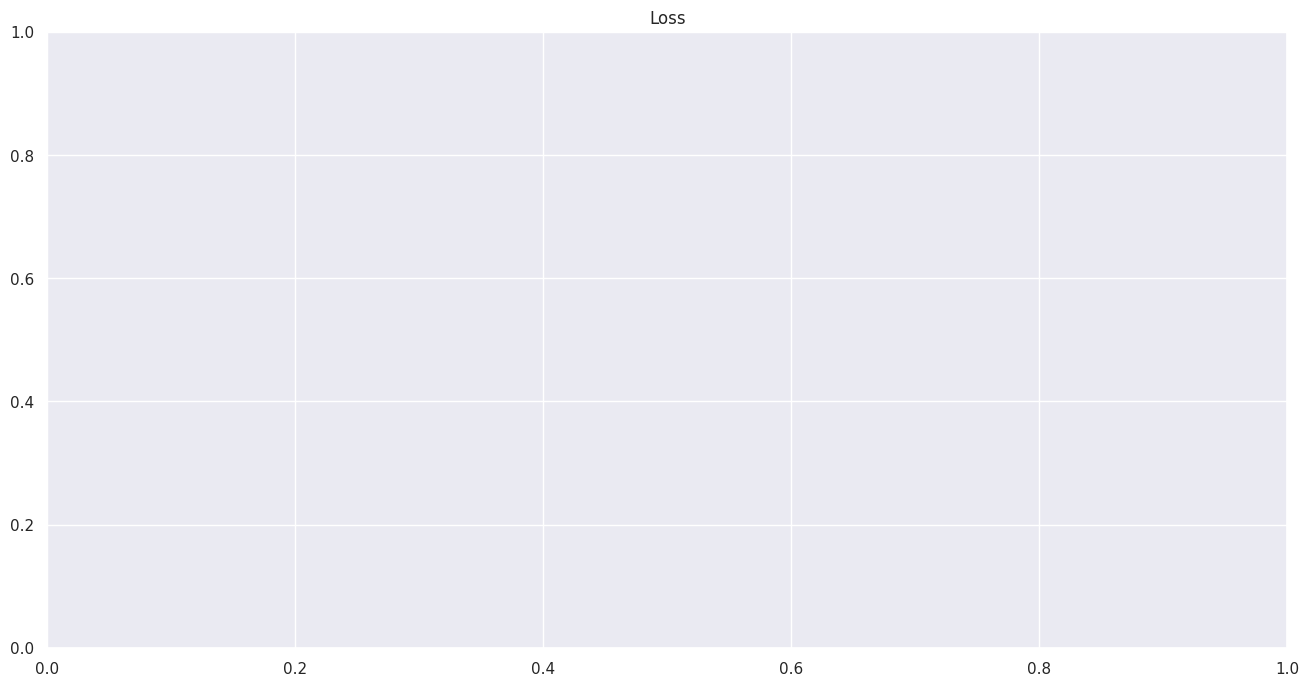

In [28]:
# Plot training & validation loss values
fig, ax = plt.subplots(figsize=(16, 8))
ax.set_title('Loss')
ax.plot(history.history['loss'], label = 'train')
ax.plot(history.history['val_loss'], label = 'test')
ax.set_ylabel('Loss')
ax.set_xlabel('Epoch')
ax.legend(['Train', 'Validation'])

## Testing

In [57]:
mse, mae, sse_, se_ = model.evaluate(test_dataset)
print("Test MSE:", mse)
print("Test MAE:", mae)
print("Test SSE:", sse_)
print("Test SE:", se_)

94/94 [==============================] - 28s 273ms/step - loss: 0.0018 - mae: 0.0229 - sse: 1.1265 - se: 0.0026
Test MSE: 0.0017684564227238297
Test MAE: 0.02285238541662693
Test SSE: 1.1264504194259644
Test SE: 0.002646772423759103


In [58]:
predictions, force_signal = [], []
for emg, f in test_dataset:
    prediction = model.predict(emg)
    predictions.append(prediction)
    force_signal.append(f)

# Converter a lista de previsões em um tensor
predictions = tf.concat(predictions, axis=0)
force_signal = tf.concat(force_signal, axis=0)

3/3 [==============================] - 1s 100ms/step


In [59]:
# predicted_test = estimator_complex.predict(emg_signal_windows_test)

In [60]:
errors = tf.keras.losses.mean_squared_error(force_signal, predictions)

print(f'mean error: {tf.reduce_mean(errors)}')
print(f'variance error: {tf.math.reduce_variance(errors)}')
print(f'r^2: {r2(force_signal, predictions)}')

mean error: 0.0017684564227238297
variance error: 1.5050201000121888e-05
r^2: 0.17046716328730693


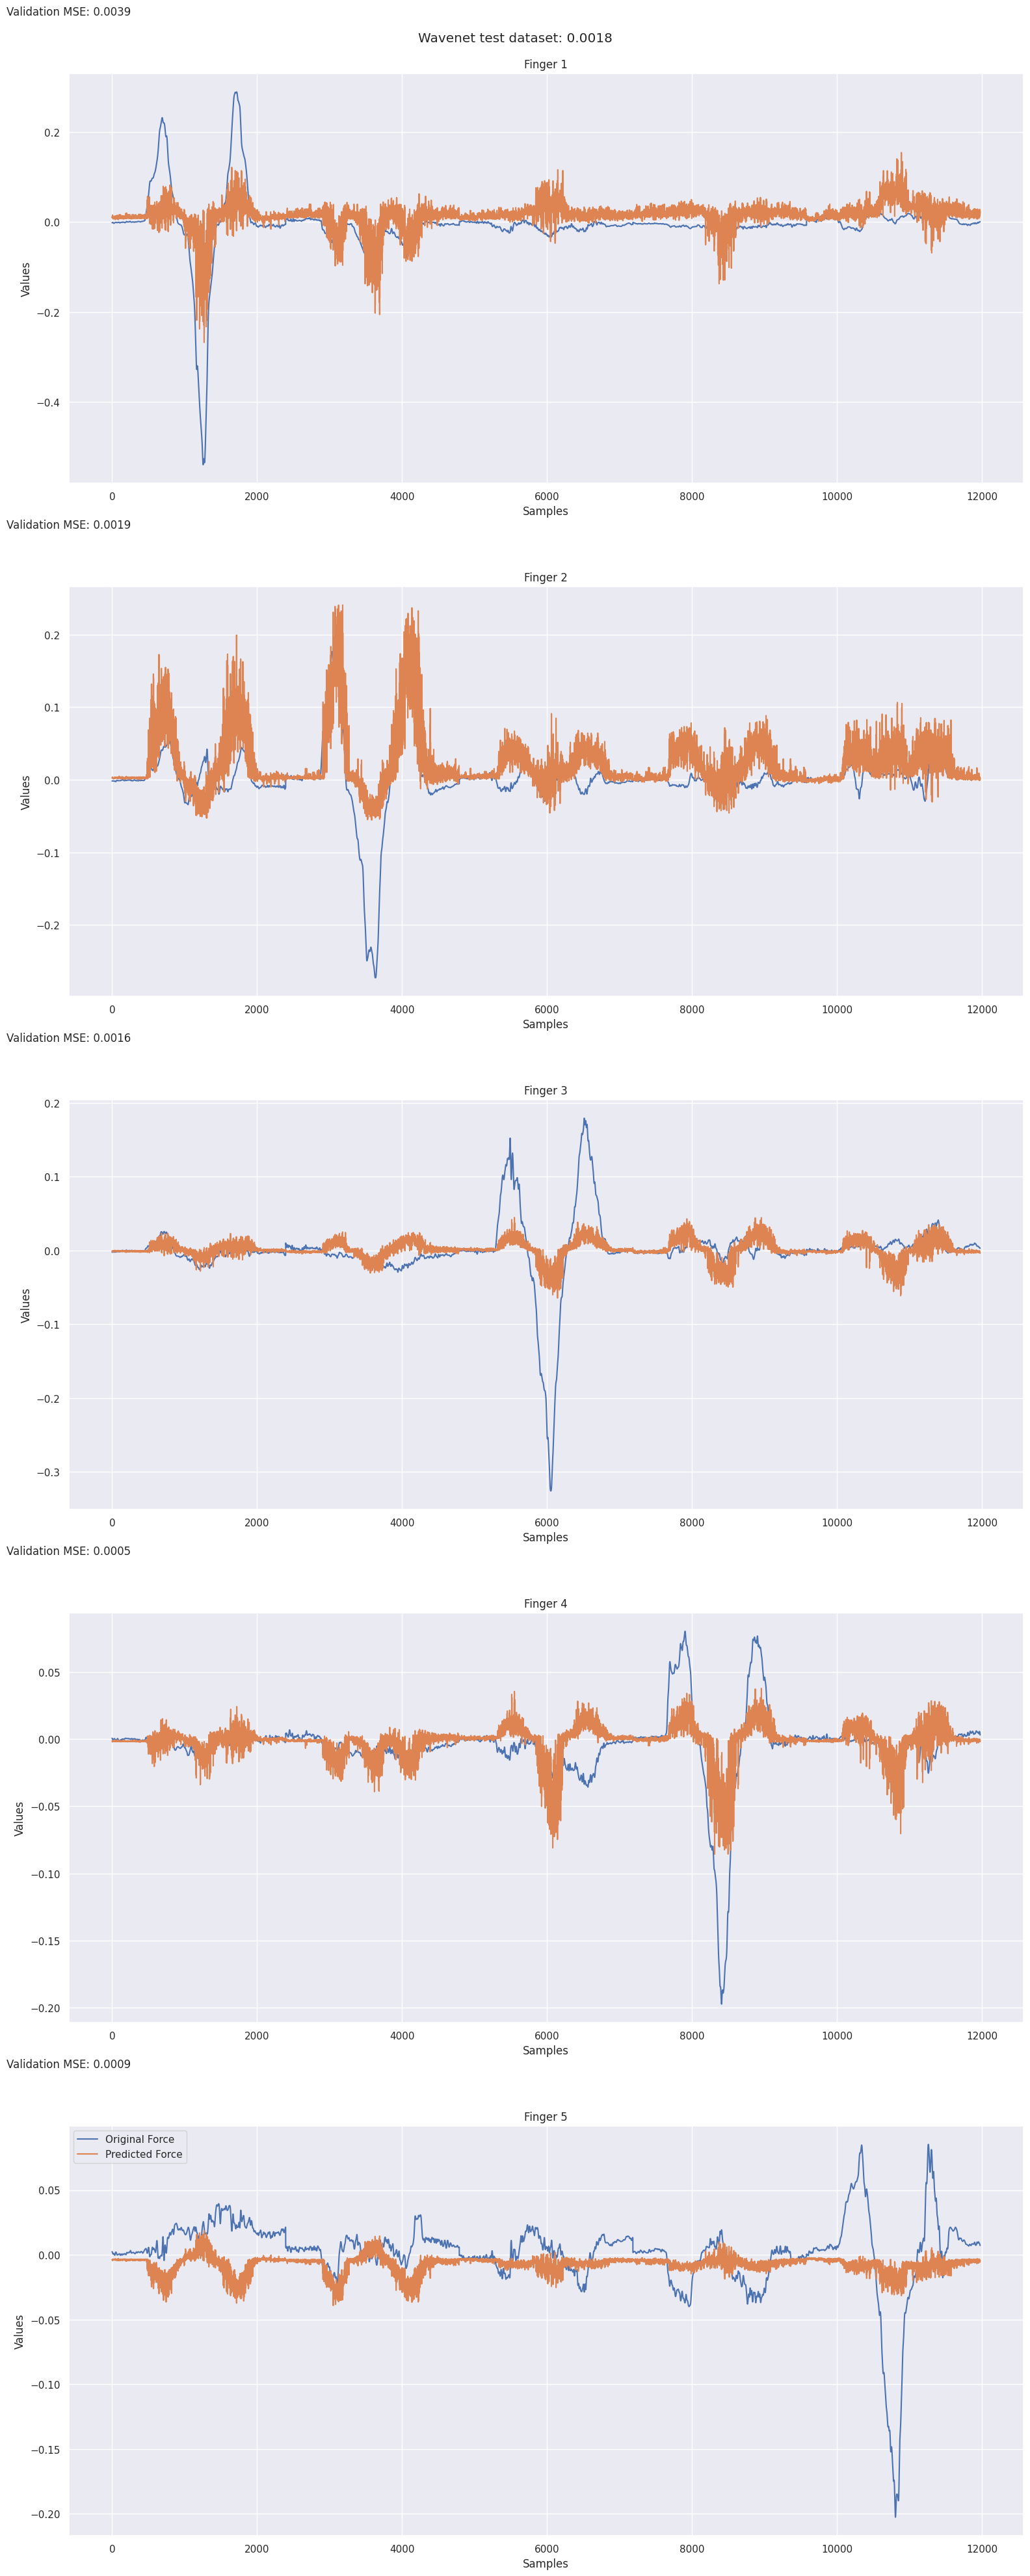

In [61]:
predicted_test = np.array(predictions)
outputs = np.array(force_signal)

# Create subplots in a 5x1 grid
fig, axes = plt.subplots(nrows=5, ncols=1, figsize=(16, 40))

mse_ = calc_mse(predicted_test, outputs)
title = f"Wavenet test dataset: {mse_:.4f}"

for i, ax in enumerate(axes):
    mse = calc_mse(predicted_test[:, i], outputs[:, i])  # Calculate MSE for each finger separately
    ax.plot(outputs[:, i], label='Original Force')
    ax.plot(predicted_test[:, i], label='Predicted Force')
    ax.text(0, 1.15, f"Validation MSE: {mse:.4f}", transform=ax.transAxes,
            ha='center', va='center', fontsize=12)
    ax.set_title(f"Finger {i+1}")
    ax.set_xlabel("Samples")
    ax.set_ylabel("Values")

plt.suptitle(title)
plt.tight_layout()
plt.legend()
plt.show()

In [62]:
def standard_error(y_true, y_pred):
    # Calcule os resíduos (diferença entre previsões e valores reais)
    y_true = tf.cast(y_true, dtype="float32")
    y_pred = tf.cast(y_pred, dtype="float32")
    residuals = y_true - y_pred

    # Calcule o desvio padrão dos resíduos (desvio padrão da amostra)
    std_deviation = tf.math.reduce_std(residuals)

    # Tamanho da amostra (número de exemplos)
    sample_size = tf.shape(residuals)[0]

    # Calcule o erro padrão da média
    standard_error = std_deviation / tf.math.sqrt(tf.cast(sample_size, dtype=tf.float32))

    return standard_error

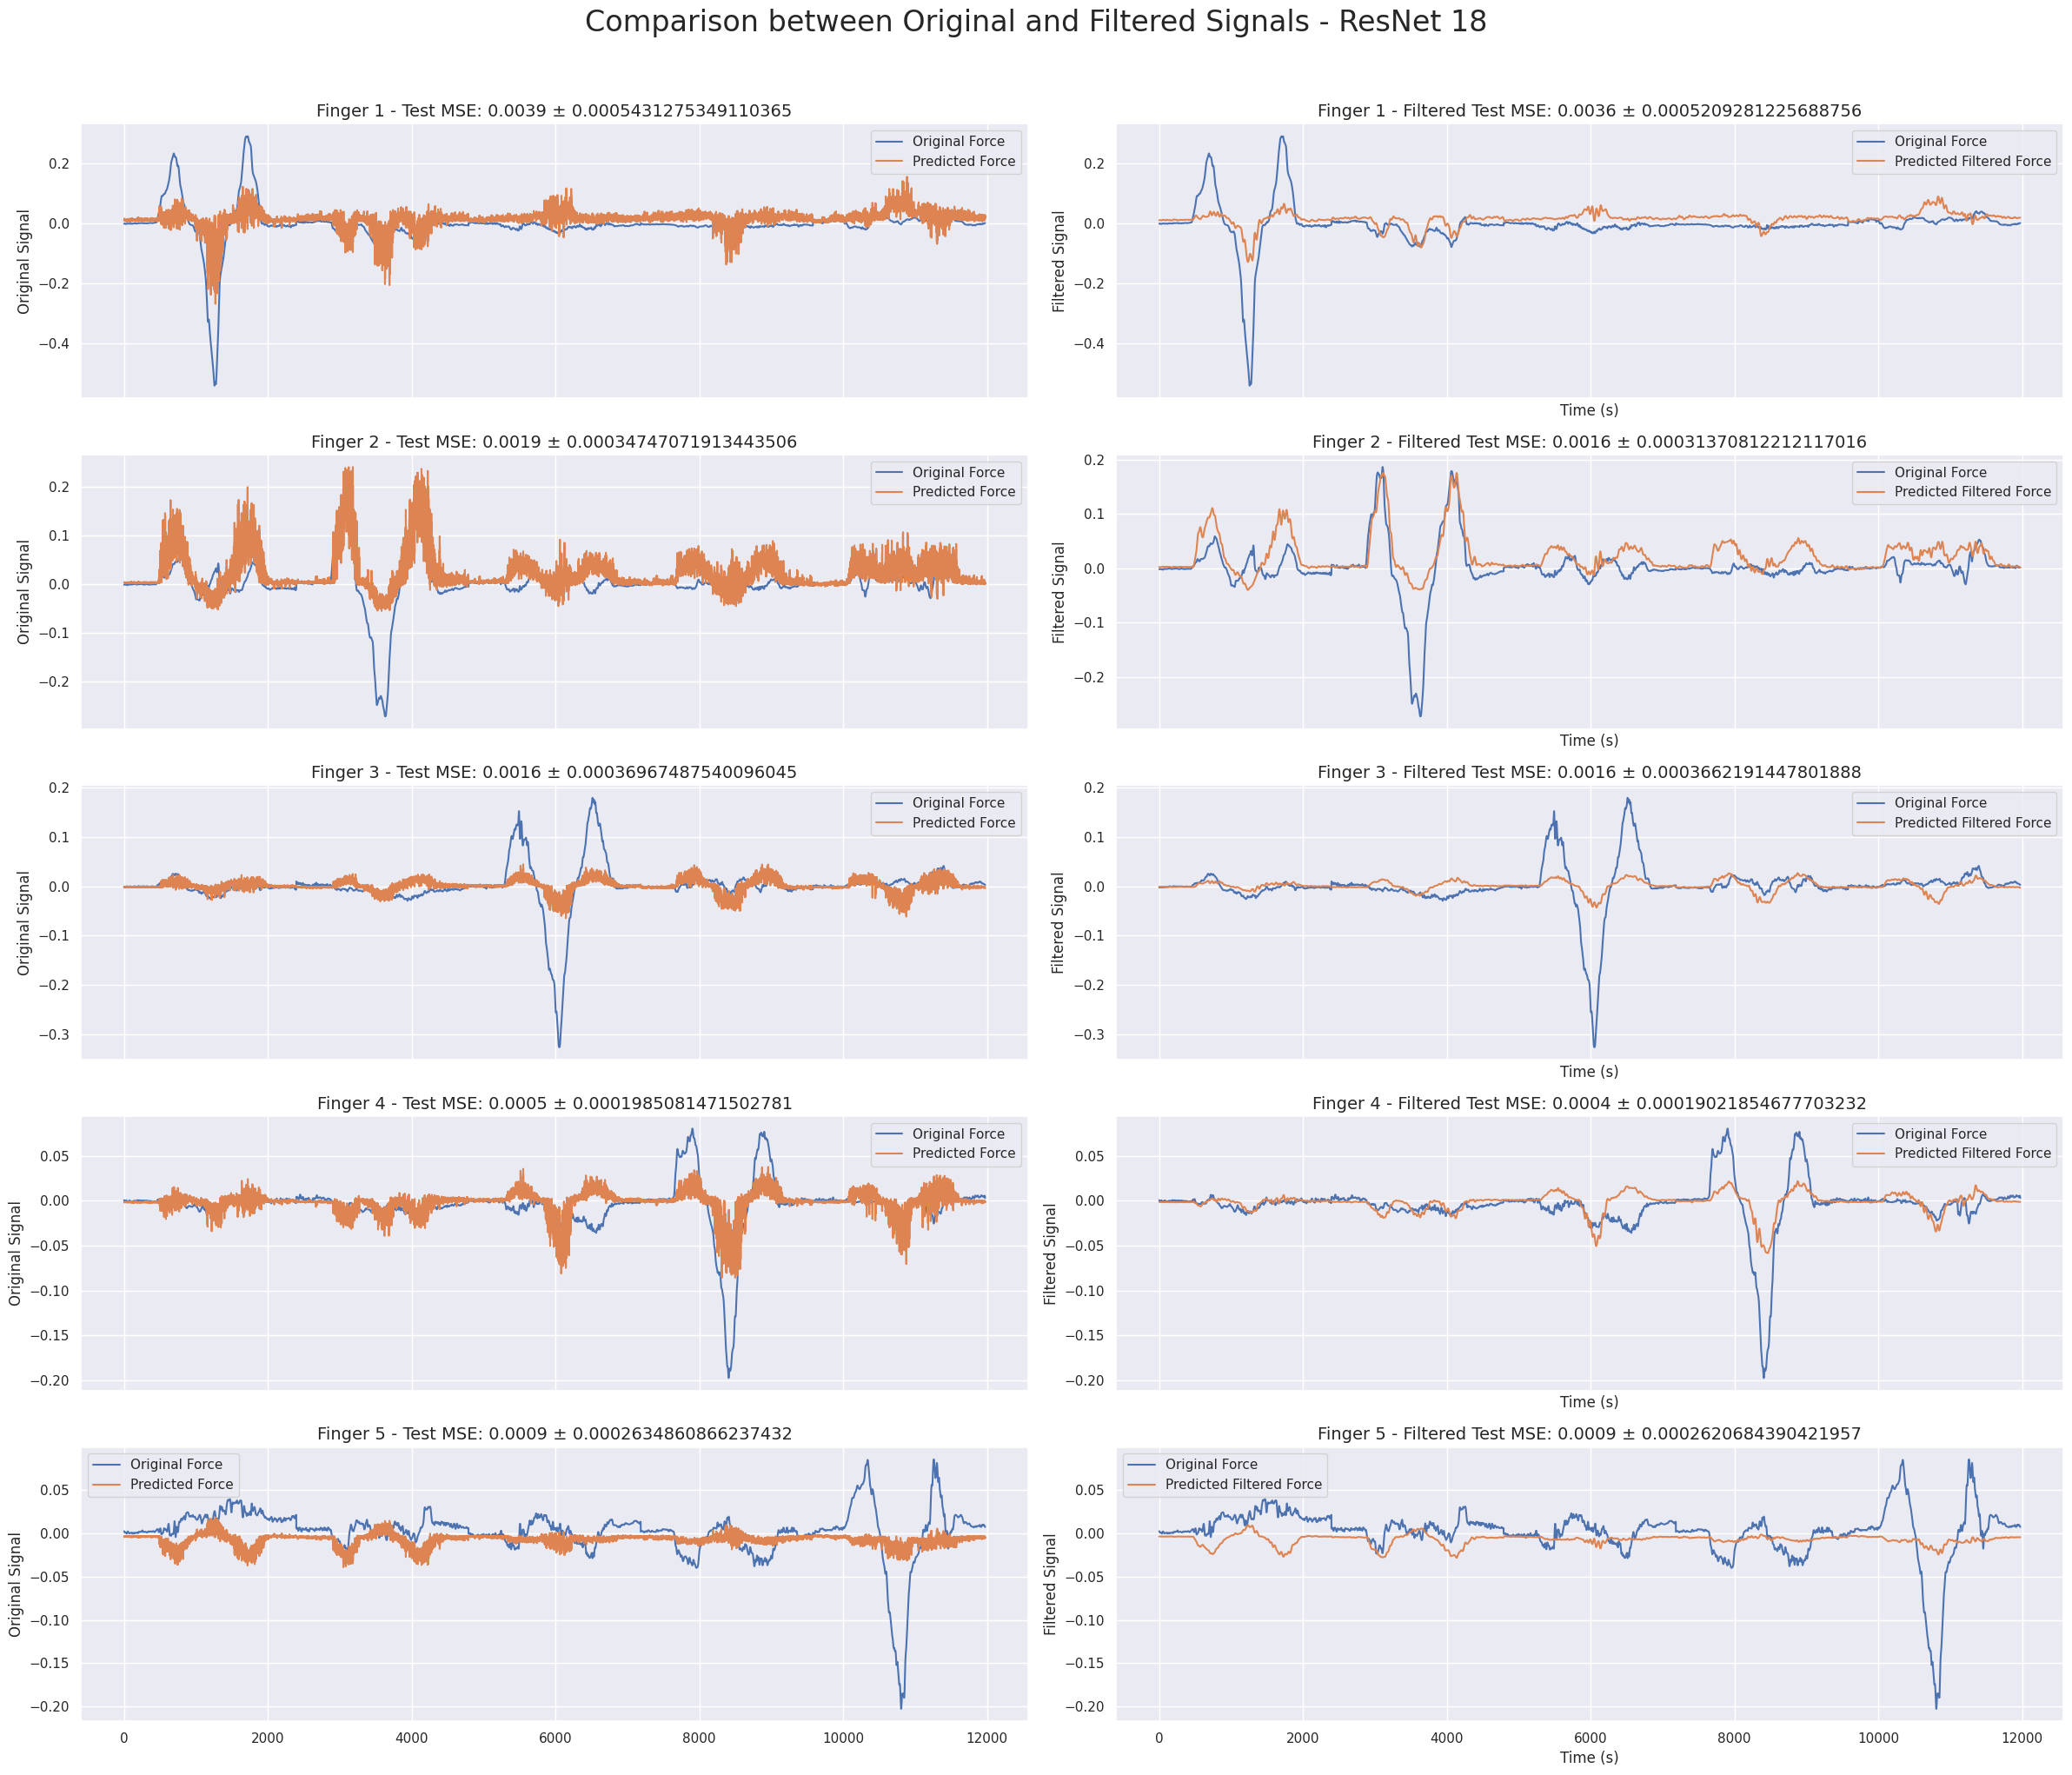

In [63]:
from scipy.signal import butter, filtfilt, iirnotch

plus_minus = "\u00B1"

def butter_lowpass(cutoff, fs, order=4):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return b, a

def butter_lowpass_filter(data, cutoff, fs, order=4):
    b, a = butter_lowpass(cutoff, fs, order=order)
    y = filtfilt(b, a, data, axis=0)
    return y

# Sample rate and desired cutoff frequency (in Hz)
fs = 2048.0
cutoff = 50.0

y = butter_lowpass_filter(predicted_test, cutoff, fs, order=4)

fig, ax = plt.subplots(5, 2, sharex=True, figsize=(24, 20))

for channel in range(5):
    # Calculate MSE for the original and filtered signals of the current channel
    mse_original = calc_mse(predicted_test[:, channel], outputs[:, channel])
    mse_filtered = calc_mse(y[:, channel], outputs[:, channel])
    std_derror_original = standard_error(predicted_test[:, channel], outputs[:, channel])
    std_derror_filtered = standard_error(y[:, channel], outputs[:, channel])

    # Plot the original signal and its prediction
    ax[channel, 0].set_title(f"Finger {channel + 1} - Test MSE: {mse_original:.4f} {plus_minus} {std_derror_original}", fontsize=14)
    ax[channel, 0].plot(outputs[:, channel], label='Original Force')
    ax[channel, 0].plot(predicted_test[:, channel], label='Predicted Force')
    ax[channel, 0].set_ylabel('Original Signal')
    ax[channel, 0].legend()

    # Plot the filtered signal and its prediction
    ax[channel, 1].set_title(f"Finger {channel + 1} - Filtered Test MSE: {mse_filtered:.4f} {plus_minus} {std_derror_filtered}", fontsize=14)
    ax[channel, 1].plot(outputs[:, channel], label='Original Force')
    ax[channel, 1].plot(y[:, channel], label='Predicted Filtered Force')
    ax[channel, 1].set_ylabel('Filtered Signal')
    ax[channel, 1].set_xlabel('Time (s)')
    ax[channel, 1].legend()

fig.suptitle("Comparison between Original and Filtered Signals - ResNet 18", fontsize=24, y=1.02)
plt.tight_layout()
plt.show()

# Training Transformer

In [64]:
analyser = signal_analyser(sequence_length=100, embed_dim=256, num_channels=1)

# Define o modelo completo
inputs = tf.keras.layers.Input(shape=(100, 16, 16, 1))

latent = analyser(inputs)
latent = layers.Dense(128, activation="linear")(latent)

outputs = layers.Dense(5, activation="linear")(latent)

coimplex_transformer = tf.keras.Model(inputs, outputs)

In [25]:
model3 = tf.keras.Sequential([
    data_augmentation,
    coimplex_transformer,
])

In [26]:
def sse(y_true, y_pred):
    return tf.reduce_sum(tf.square(y_true - y_pred))

### Callbacks

In [27]:
callback = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath="gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/transformers/all_fingers/",
        monitor="val_loss",
        verbose=1,
        save_best_only=True,
        save_weights_only=True,
        mode="min",
        save_format="tf.saved_model"
    ),
    tf.keras.callbacks.TensorBoard(
      log_dir='gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_tensorboard/transformers/all_fingers/',
      histogram_freq=0,
      write_graph=True,
      write_images=False,
      write_steps_per_second=False,
      update_freq='epoch',
      profile_batch=0,
      embeddings_freq=0,
      embeddings_metadata=None,
    ),
    tf.keras.callbacks.EarlyStopping(
      patience=20,
      restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.75,
        patience=5,
        min_lr=1e-8,
    ),
]

In [33]:
# Compilar o modelo
optimizer = keras.optimizers.Adam(learning_rate=1e-3)
model3.compile(optimizer=optimizer, loss='mse', metrics=['mae', sse, se])
# Fit data to model

history = model3.fit(
    train_dataset,
    epochs=200,
    validation_data=val_dataset,
    callbacks=callback,
)

Epoch 1/200
    280/Unknown - 117s 321ms/step - loss: 0.0880 - mae: 0.1424 - sse: 56.3135 - se: 0.0156
Epoch 1: val_loss improved from inf to 0.00516, saving model to gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/transformers/all_fingers/
281/281 [==============================] - 192s 586ms/step - loss: 0.0878 - mae: 0.1422 - sse: 56.1170 - se: 0.0155 - val_loss: 0.0052 - val_mae: 0.0522 - val_sse: 3.2856 - val_se: 0.0052 - lr: 0.0010
Epoch 2/200
281/281 [==============================] - ETA: 0s - loss: 0.0032 - mae: 0.0389 - sse: 2.0574 - se: 0.0046
Epoch 2: val_loss improved from 0.00516 to 0.00338, saving model to gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/transformers/all_fingers/
281/281 [==============================] - 12s 42ms/step - loss: 0.0032 - mae: 0.0389 - sse: 2.0574 - se: 0.0046 - val_loss: 0.0034 - val_mae: 0.0391 - val_sse: 2.1504 - val_se: 0.0041 - lr: 0.0010
Epoch 3/200
281/281 [==============================] - ETA: 0s 

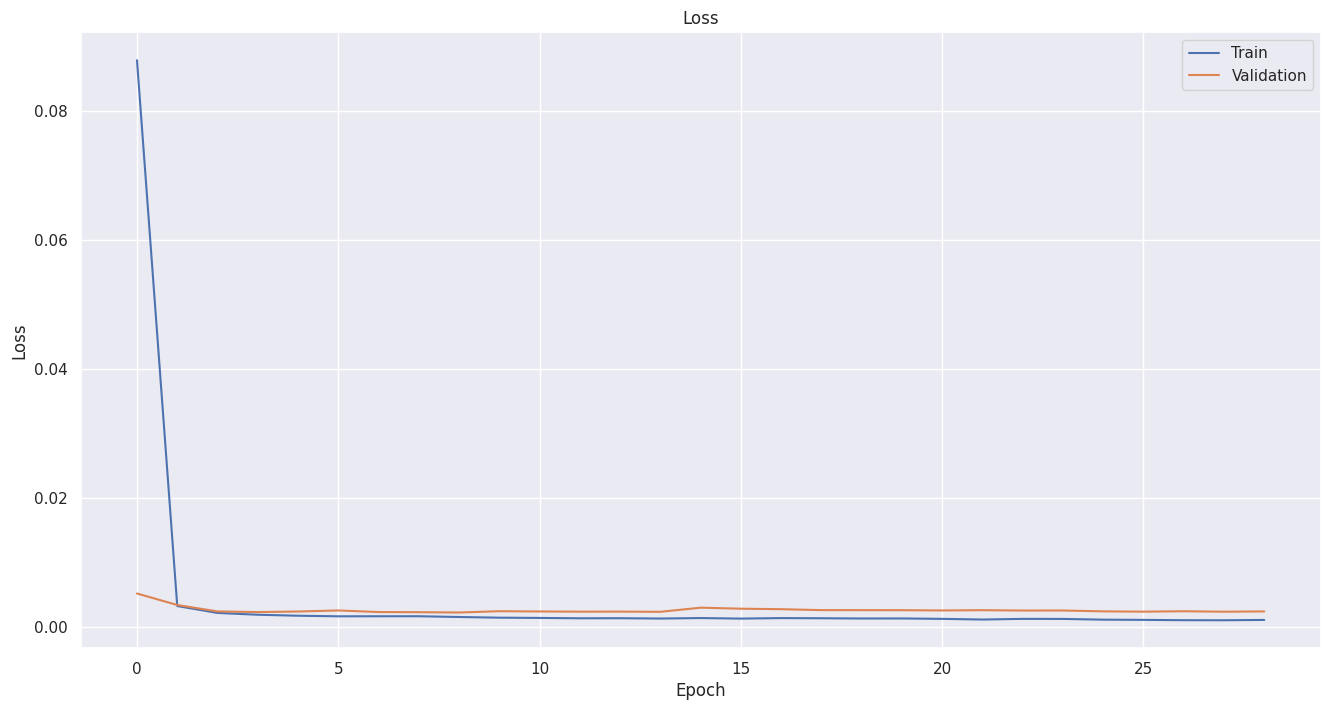

In [34]:
# Plot training & validation loss values
fig, ax = plt.subplots(figsize=(16, 8))
ax.set_title('Loss')
ax.plot(history.history['loss'], label = 'train')
ax.plot(history.history['val_loss'], label = 'test')
ax.set_ylabel('Loss')
ax.set_xlabel('Epoch')
ax.legend(['Train', 'Validation'])

In [35]:
mse, mae, sse_, se_ = model3.evaluate(test_dataset)
print("Test MSE:", mse)
print("Test MAE:", mae)
print("Test SSE:", sse_)
print("Test SSE:", se_)

94/94 [==============================] - 38s 345ms/step - loss: 0.0021 - mae: 0.0269 - sse: 1.3458 - se: 0.0027
Test MSE: 0.002112771850079298
Test MAE: 0.02687431126832962
Test SSE: 1.3457680940628052
Test SSE: 0.0027161049656569958


In [36]:
predictions, force_signal = [], []
for emg, f in test_dataset:
    prediction = model3.predict(emg)
    predictions.append(prediction)
    force_signal.append(f)

# Converter a lista de previsões em um tensor
predictions = tf.concat(predictions, axis=0)
force_signal = tf.concat(force_signal, axis=0)

3/3 [==============================] - 0s 6ms/step


In [37]:
# predicted_test = estimator_complex.predict(emg_signal_windows_test)

In [38]:
errors = tf.keras.losses.mean_squared_error(force_signal, predictions)

print(f'mean error: {tf.reduce_mean(errors)}')
print(f'variance error: {tf.math.reduce_variance(errors)}')
print(f'r^2: {r2(force_signal, predictions)}')

mean error: 0.0021127716172486544
variance error: 2.852364741556812e-05
r^2: -0.015060758081702796


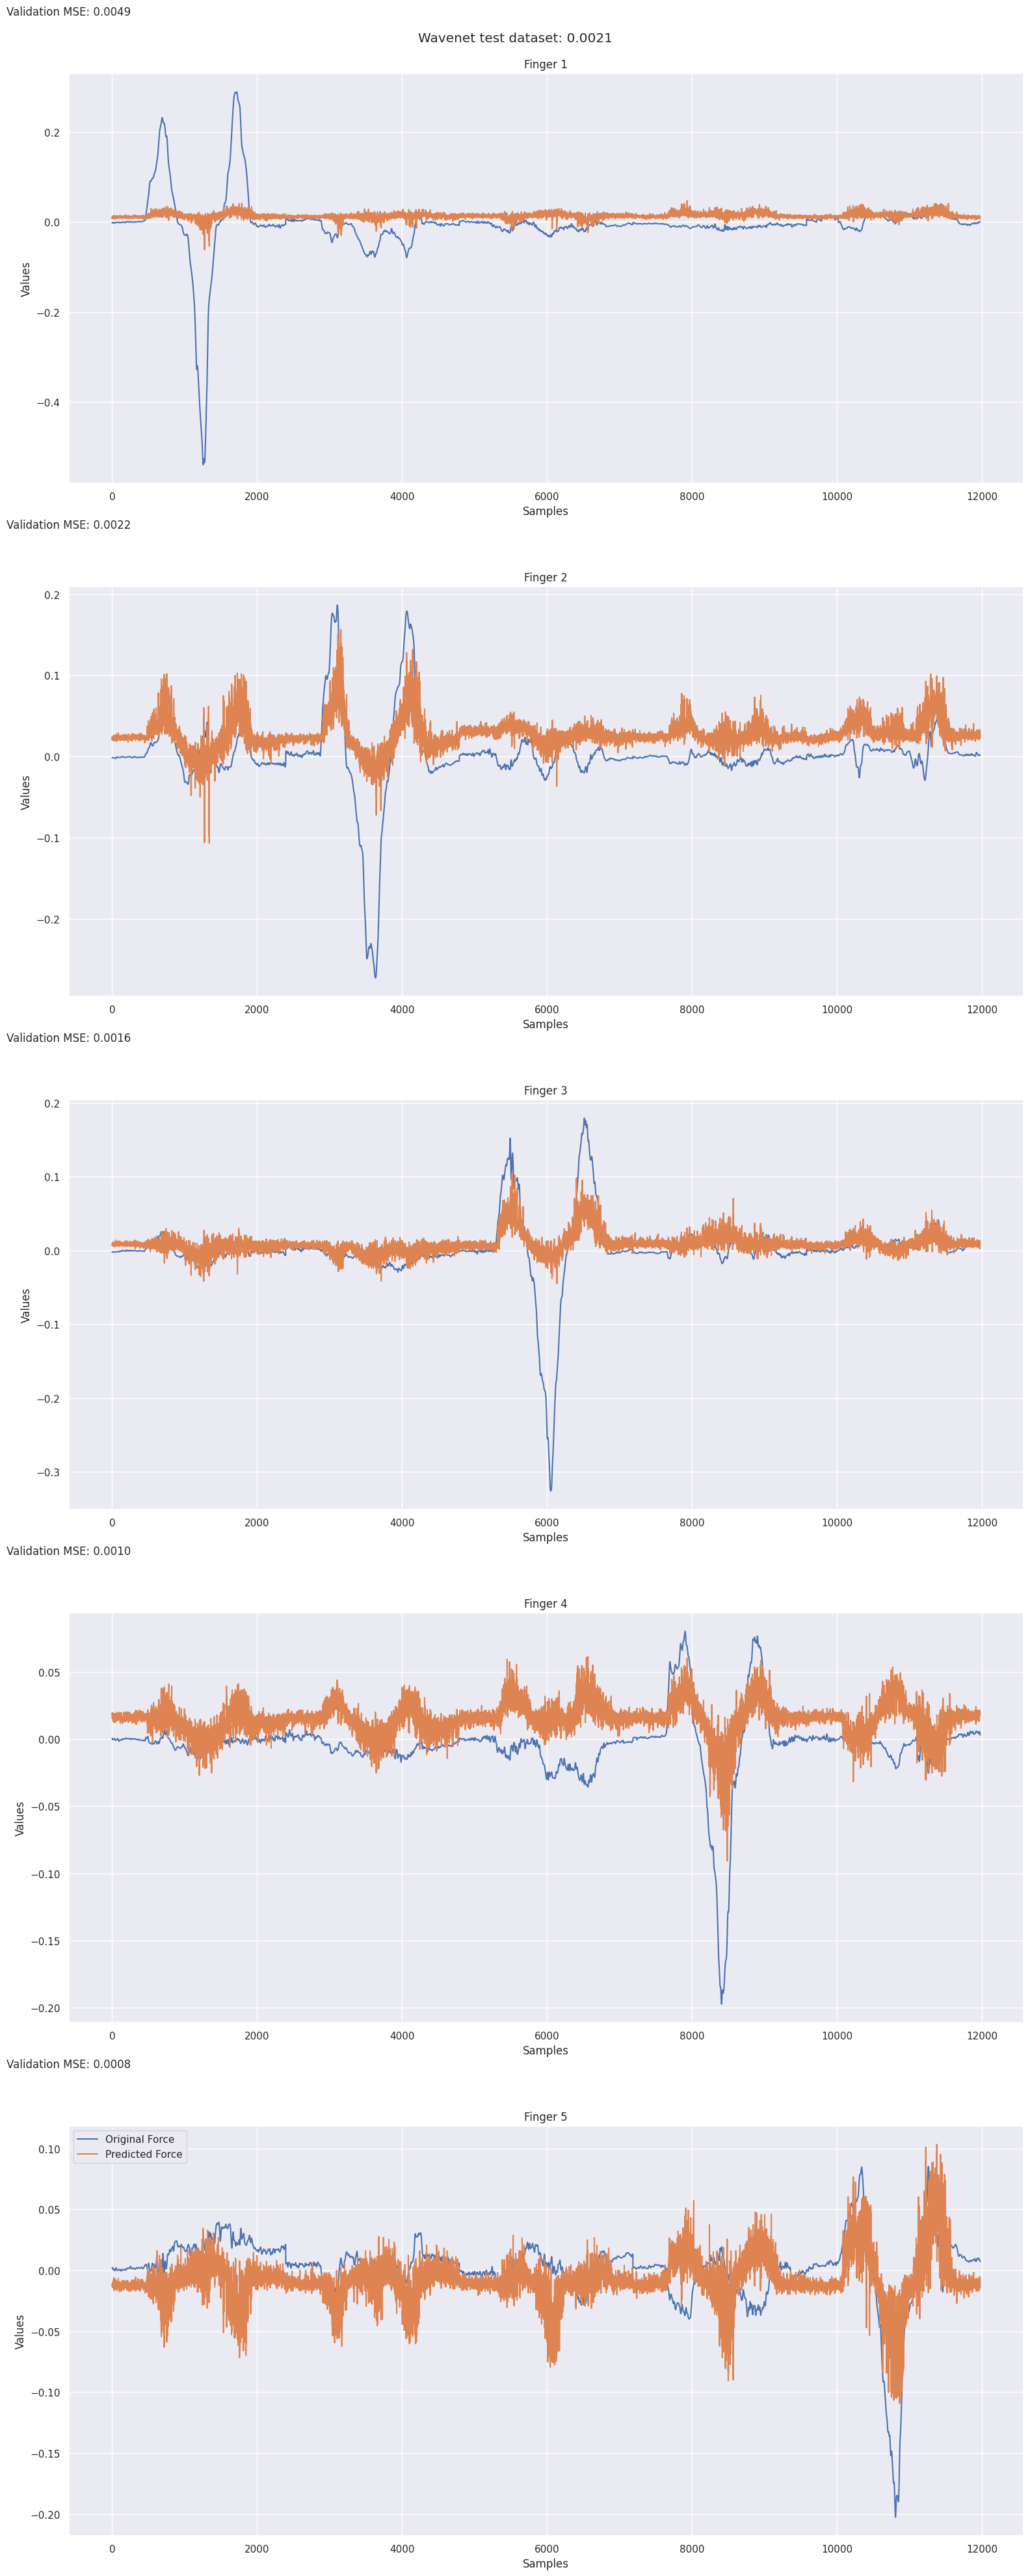

In [39]:
predicted_test = np.array(predictions)
outputs = np.array(force_signal)

# Create subplots in a 5x1 grid
fig, axes = plt.subplots(nrows=5, ncols=1, figsize=(16, 40))

mse_ = calc_mse(predicted_test, outputs)
title = f"Wavenet test dataset: {mse_:.4f}"

for i, ax in enumerate(axes):
    mse = calc_mse(predicted_test[:, i], outputs[:, i])  # Calculate MSE for each finger separately
    ax.plot(outputs[:, i], label='Original Force')
    ax.plot(predicted_test[:, i], label='Predicted Force')
    ax.text(0, 1.15, f"Validation MSE: {mse:.4f}", transform=ax.transAxes,
            ha='center', va='center', fontsize=12)
    ax.set_title(f"Finger {i+1}")
    ax.set_xlabel("Samples")
    ax.set_ylabel("Values")

plt.suptitle(title)
plt.tight_layout()
plt.legend()
plt.show()

In [40]:
def standard_error(y_true, y_pred):
    # Calcule os resíduos (diferença entre previsões e valores reais)
    y_true = tf.cast(y_true, dtype="float32")
    y_pred = tf.cast(y_pred, dtype="float32")
    residuals = y_true - y_pred

    # Calcule o desvio padrão dos resíduos (desvio padrão da amostra)
    std_deviation = tf.math.reduce_std(residuals)

    # Tamanho da amostra (número de exemplos)
    sample_size = tf.shape(residuals)[0]

    # Calcule o erro padrão da média
    standard_error = std_deviation / tf.math.sqrt(tf.cast(sample_size, dtype=tf.float32))

    return standard_error

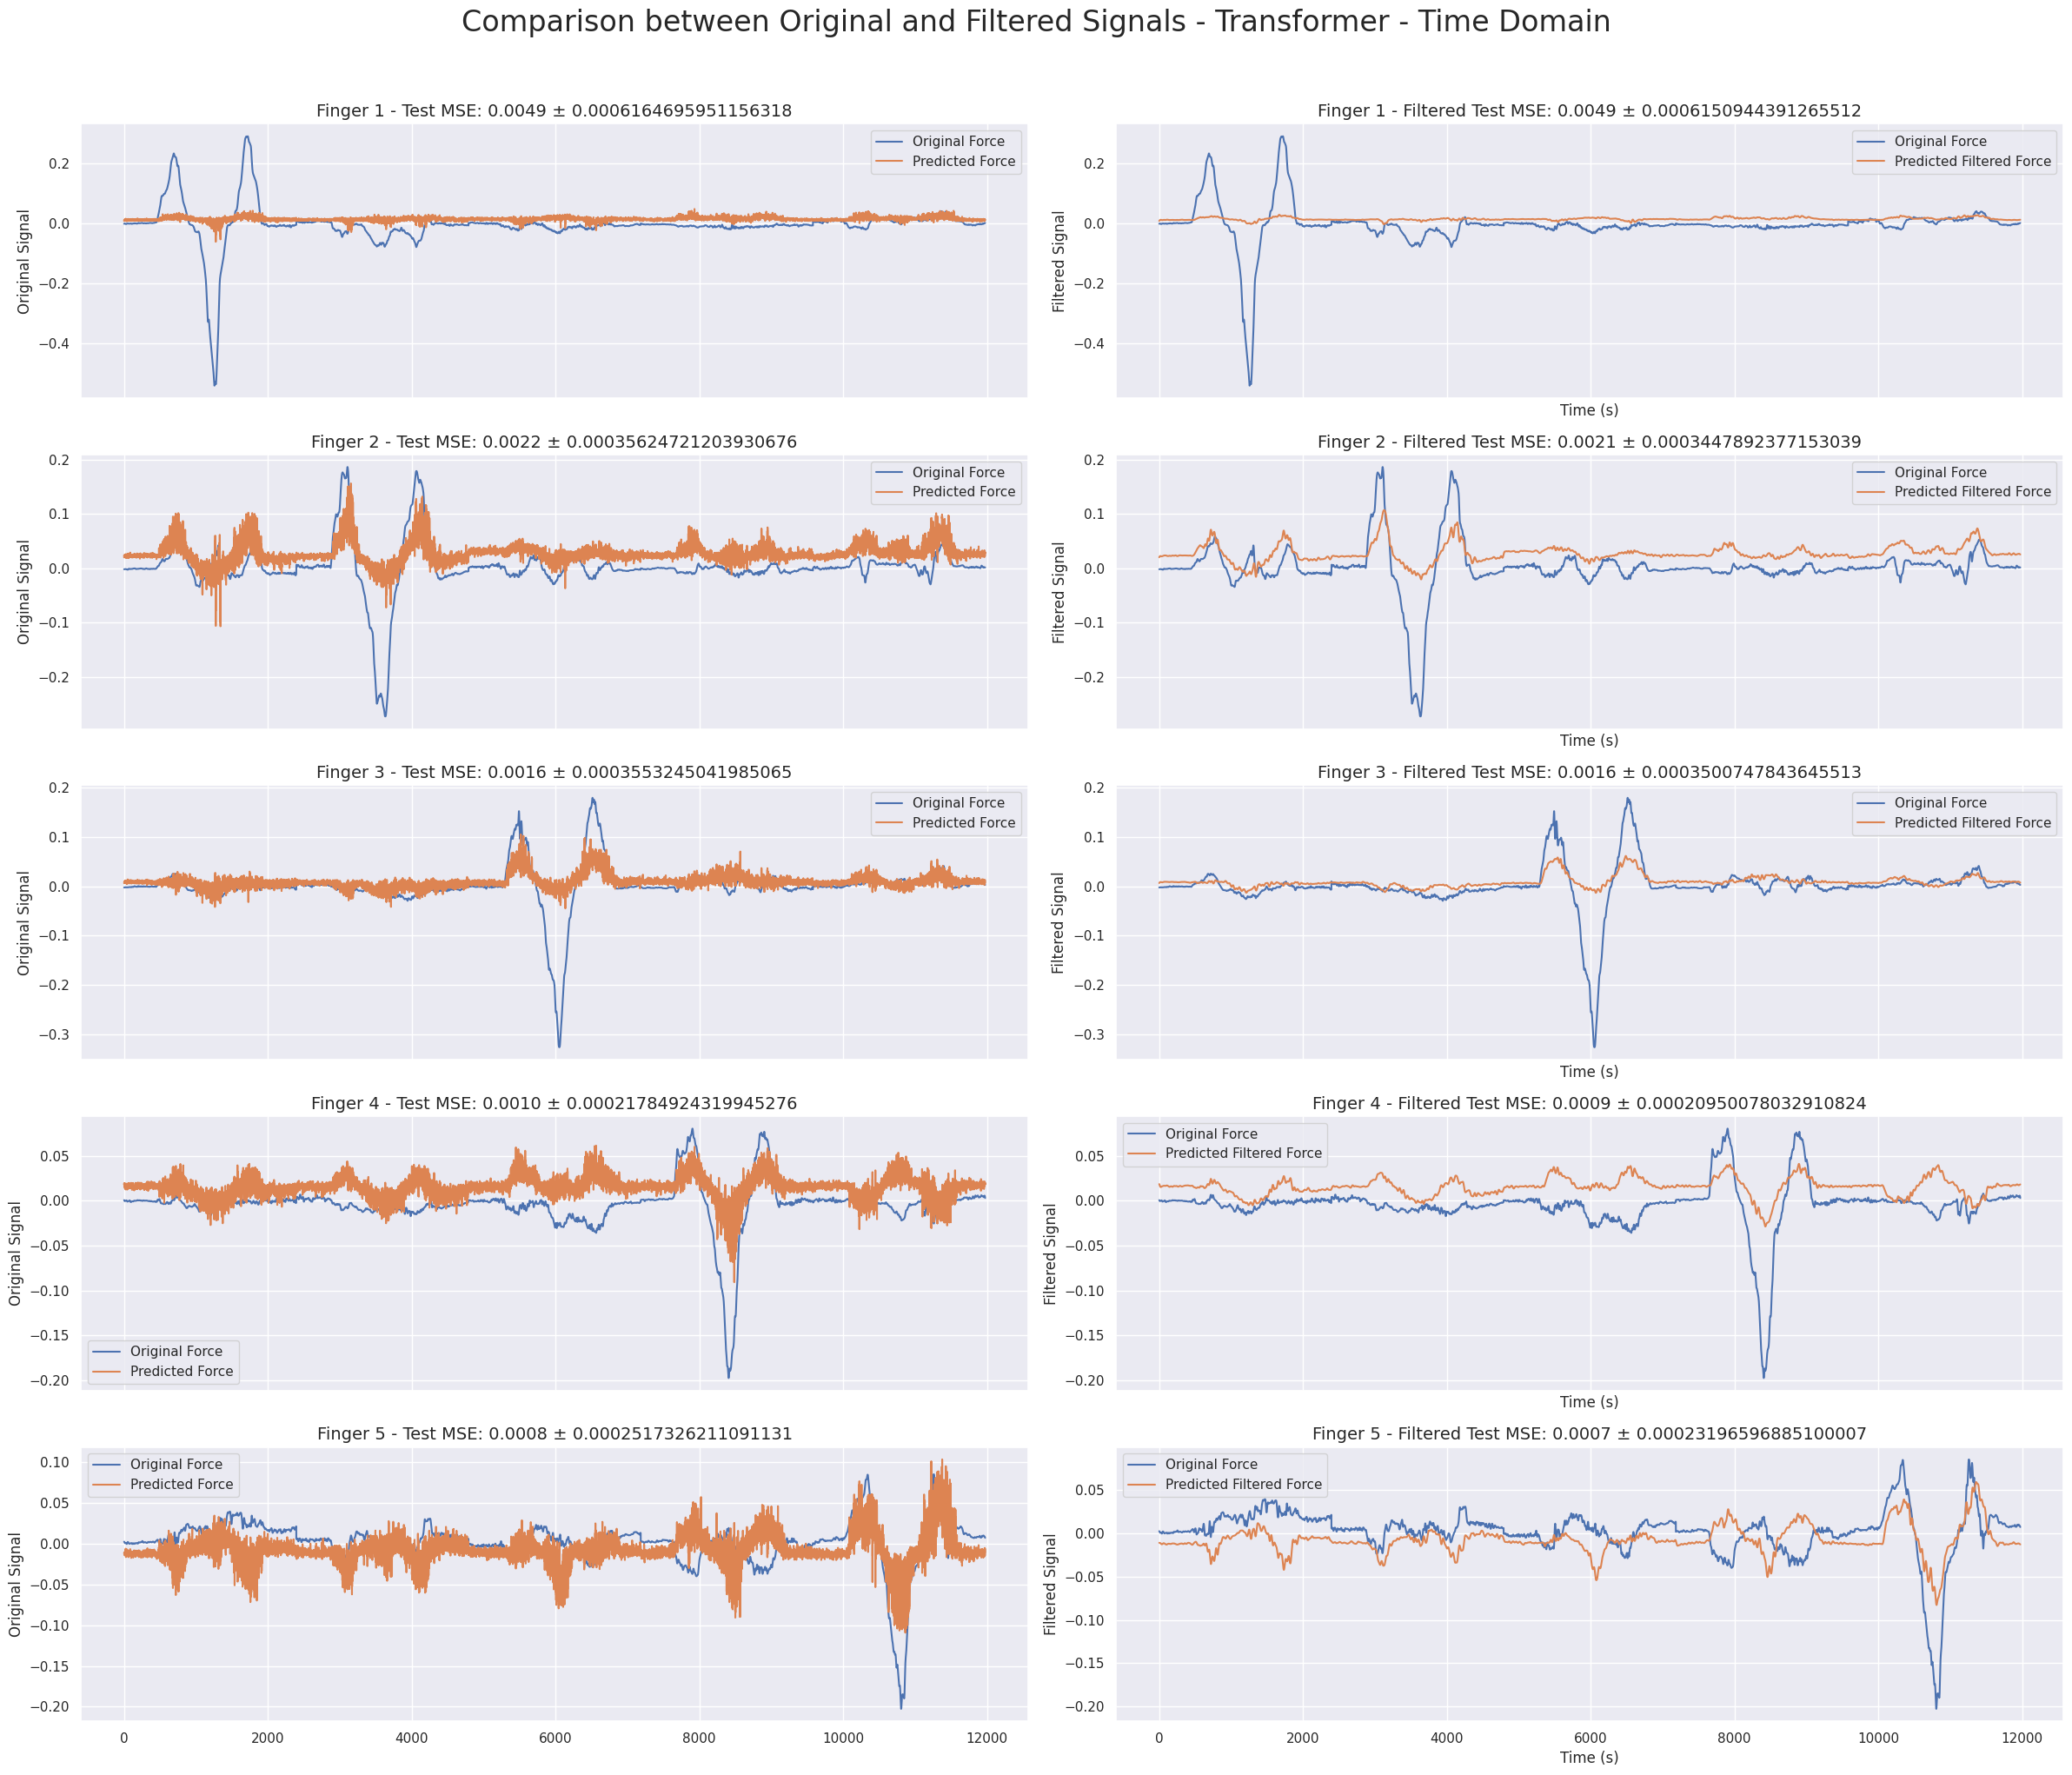

In [41]:
from scipy.signal import butter, filtfilt, iirnotch

plus_minus = "\u00B1"

def butter_lowpass(cutoff, fs, order=4):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return b, a

def butter_lowpass_filter(data, cutoff, fs, order=4):
    b, a = butter_lowpass(cutoff, fs, order=order)
    y = filtfilt(b, a, data, axis=0)
    return y

# Sample rate and desired cutoff frequency (in Hz)
fs = 2048.0
cutoff = 50.0

y = butter_lowpass_filter(predicted_test, cutoff, fs, order=4)

fig, ax = plt.subplots(5, 2, sharex=True, figsize=(24, 20))

for channel in range(5):
    # Calculate MSE for the original and filtered signals of the current channel
    mse_original = calc_mse(predicted_test[:, channel], outputs[:, channel])
    mse_filtered = calc_mse(y[:, channel], outputs[:, channel])
    std_derror_original = standard_error(predicted_test[:, channel], outputs[:, channel])
    std_derror_filtered = standard_error(y[:, channel], outputs[:, channel])

    # Plot the original signal and its prediction
    ax[channel, 0].set_title(f"Finger {channel + 1} - Test MSE: {mse_original:.4f} {plus_minus} {std_derror_original}", fontsize=14)
    ax[channel, 0].plot(outputs[:, channel], label='Original Force')
    ax[channel, 0].plot(predicted_test[:, channel], label='Predicted Force')
    ax[channel, 0].set_ylabel('Original Signal')
    ax[channel, 0].legend()

    # Plot the filtered signal and its prediction
    ax[channel, 1].set_title(f"Finger {channel + 1} - Filtered Test MSE: {mse_filtered:.4f} {plus_minus} {std_derror_filtered}", fontsize=14)
    ax[channel, 1].plot(outputs[:, channel], label='Original Force')
    ax[channel, 1].plot(y[:, channel], label='Predicted Filtered Force')
    ax[channel, 1].set_ylabel('Filtered Signal')
    ax[channel, 1].set_xlabel('Time (s)')
    ax[channel, 1].legend()

fig.suptitle("Comparison between Original and Filtered Signals - Transformer - Time Domain", fontsize=24, y=1.02)
plt.tight_layout()
plt.show()

# Training Complex Transformer

In [42]:
analyser = signal_analyser(sequence_length=100, embed_dim=256, num_channels=2)

# Define o modelo completo
inputs = tf.keras.layers.Input(shape=(100, 16, 16, 1))
fft_inputs = tf.cast(
    tf.squeeze(inputs, axis=-1), dtype=tf.complex64, name=None
)
complex_inputs = fft_tensor(fft_inputs)

latent = analyser(complex_inputs)
latent = layers.Dense(128, activation="linear")(latent)

outputs = layers.Dense(5, activation="linear")(latent)

coimplex_transformer = tf.keras.Model(inputs, outputs)

In [43]:
model4 = tf.keras.Sequential([
    data_augmentation,
    coimplex_transformer,
])

In [44]:
def sse(y_true, y_pred):
    return tf.reduce_sum(tf.square(y_true - y_pred))

### Callbacks

In [45]:
callback = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath="gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/transformers_complexo/all_fingers/",
        monitor="val_loss",
        verbose=1,
        save_best_only=True,
        save_weights_only=True,
        mode="min",
        save_format="tf.saved_model"
    ),
    tf.keras.callbacks.TensorBoard(
      log_dir='gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_tensorboard/transformers_complexo/all_fingers/',
      histogram_freq=0,
      write_graph=True,
      write_images=False,
      write_steps_per_second=False,
      update_freq='epoch',
      profile_batch=0,
      embeddings_freq=0,
      embeddings_metadata=None,
    ),
    tf.keras.callbacks.EarlyStopping(
      patience=20,
      restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.75,
        patience=5,
        min_lr=1e-8,
    ),
]

In [46]:
# Compilar o modelo
optimizer = keras.optimizers.Adam(learning_rate=1e-3)
model4.compile(optimizer=optimizer, loss='mse', metrics=['mae', sse, se])
# Fit data to model

history = model4.fit(
    train_dataset,
    epochs=200,
    validation_data=val_dataset,
    callbacks=callback,
)

Epoch 1/200
    281/Unknown - 23s 77ms/step - loss: 0.1512 - mae: 0.2208 - sse: 96.6281 - se: 0.0239
Epoch 1: val_loss improved from inf to 0.04658, saving model to gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/transformers_complexo/all_fingers/
281/281 [==============================] - 31s 105ms/step - loss: 0.1512 - mae: 0.2208 - sse: 96.6281 - se: 0.0239 - val_loss: 0.0466 - val_mae: 0.1629 - val_sse: 29.6703 - val_se: 0.0167 - lr: 0.0010
Epoch 2/200
281/281 [==============================] - ETA: 0s - loss: 0.0139 - mae: 0.0889 - sse: 8.8688 - se: 0.0100
Epoch 2: val_loss improved from 0.04658 to 0.01224, saving model to gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/transformers_complexo/all_fingers/
281/281 [==============================] - 28s 99ms/step - loss: 0.0139 - mae: 0.0889 - sse: 8.8688 - se: 0.0100 - val_loss: 0.0122 - val_mae: 0.0708 - val_sse: 7.7974 - val_se: 0.0081 - lr: 0.0010
Epoch 3/200
281/281 [==========================

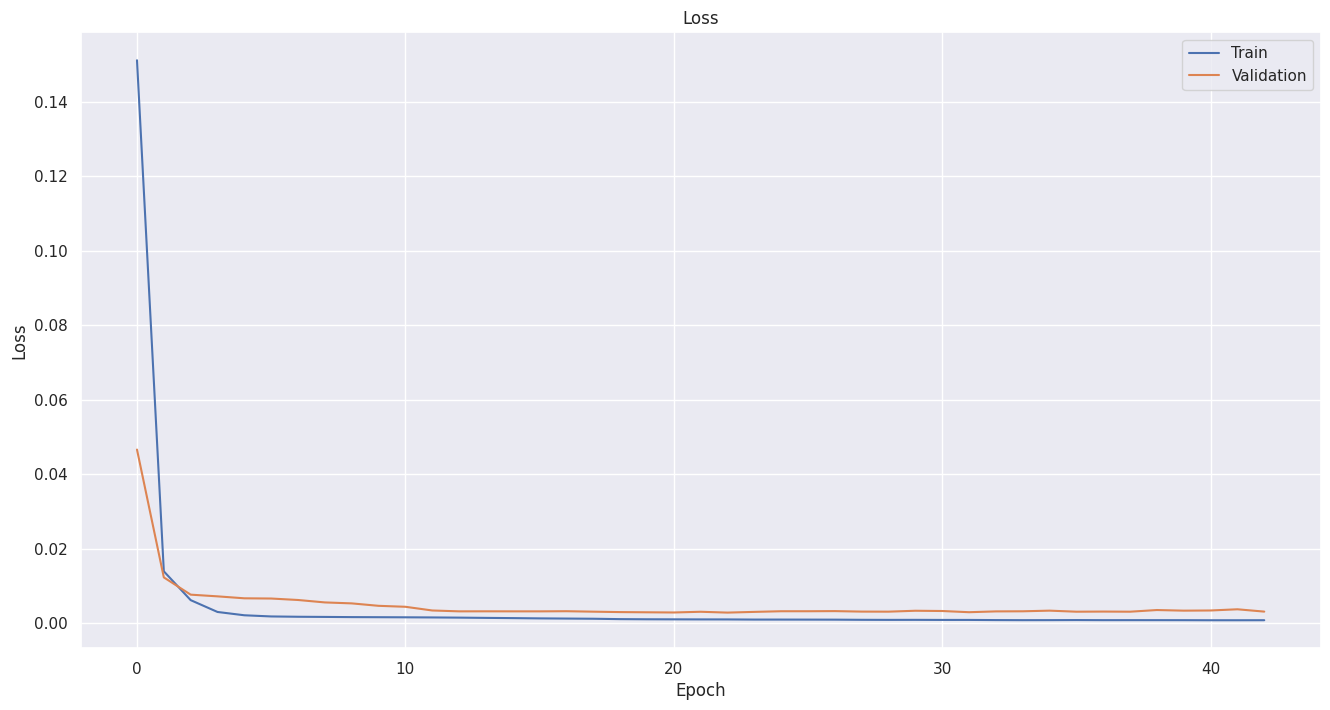

In [47]:
# Plot training & validation loss values
fig, ax = plt.subplots(figsize=(16, 8))
ax.set_title('Loss')
ax.plot(history.history['loss'], label = 'train')
ax.plot(history.history['val_loss'], label = 'test')
ax.set_ylabel('Loss')
ax.set_xlabel('Epoch')
ax.legend(['Train', 'Validation'])

## Testing

In [48]:
mse, mae, sse_, se_ = model3.evaluate(test_dataset)
print("Test MSE:", mse)
print("Test MAE:", mae)
print("Test SSE:", sse_)
print("Test SE:", se_)

94/94 [==============================] - 16s 149ms/step - loss: 0.0021 - mae: 0.0269 - sse: 1.3458 - se: 0.0027
Test MSE: 0.002112771850079298
Test MAE: 0.02687431126832962
Test SSE: 1.3457680940628052
Test SE: 0.0027161049656569958


In [49]:
predictions, force_signal = [], []
for emg, f in test_dataset:
    prediction = model4.predict(emg)
    predictions.append(prediction)
    force_signal.append(f)

# Converter a lista de previsões em um tensor
predictions = tf.concat(predictions, axis=0)
force_signal = tf.concat(force_signal, axis=0)

3/3 [==============================] - 0s 9ms/step


In [50]:
# predicted_test = estimator_complex.predict(emg_signal_windows_test)

In [51]:
errors = tf.keras.losses.mean_squared_error(force_signal, predictions)

print(f'mean error: {tf.reduce_mean(errors)}')
print(f'variance error: {tf.math.reduce_variance(errors)}')
print(f'r^2: {r2(force_signal, predictions)}')

mean error: 0.002748963190242648
variance error: 1.962015994649846e-05
r^2: -0.32114013751442033


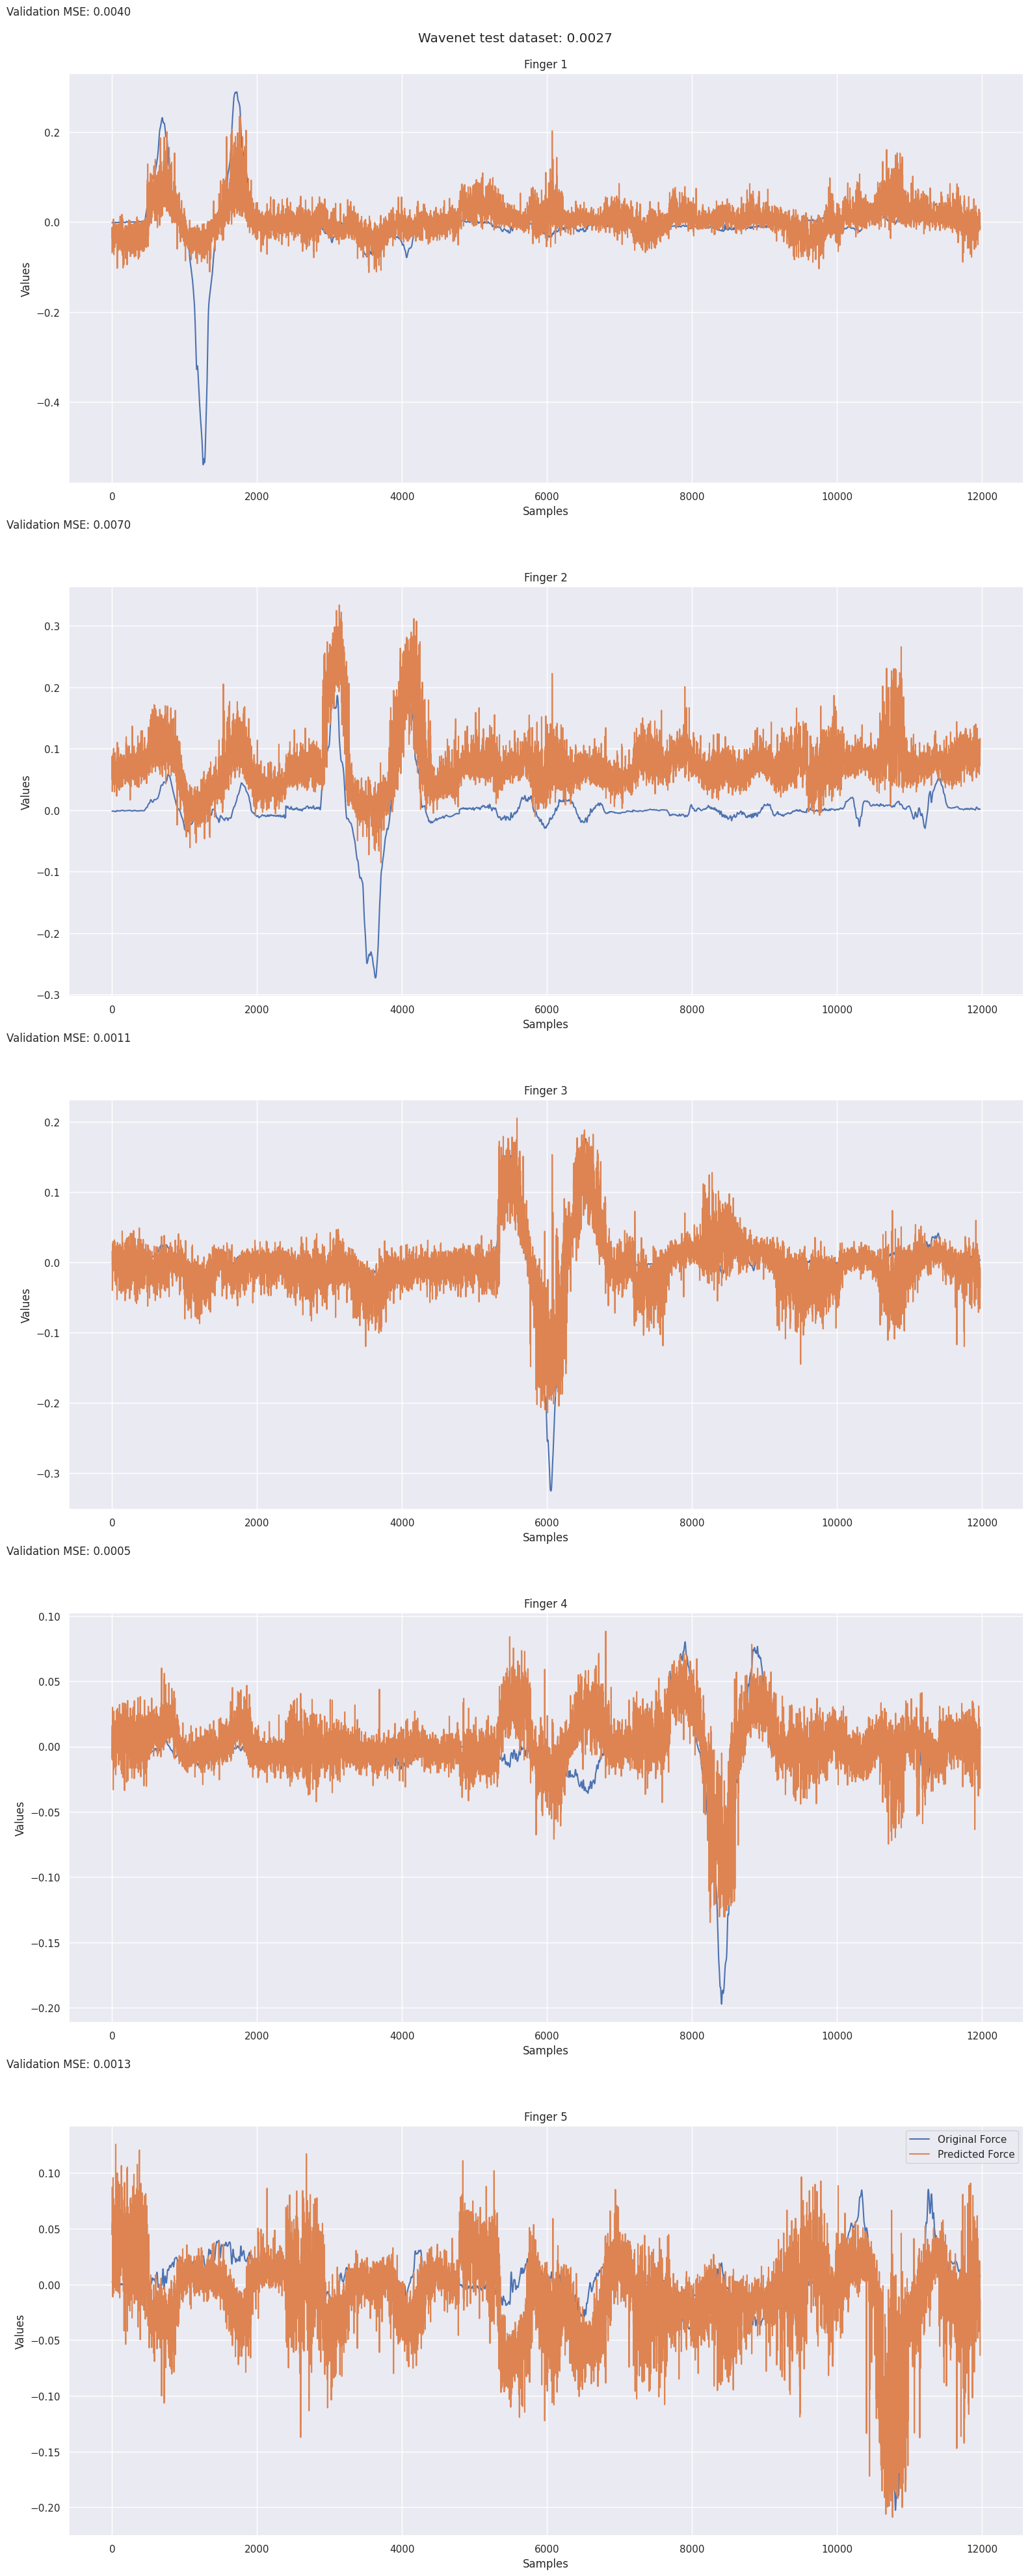

In [52]:
predicted_test = np.array(predictions)
outputs = np.array(force_signal)

# Create subplots in a 5x1 grid
fig, axes = plt.subplots(nrows=5, ncols=1, figsize=(16, 40))

mse_ = calc_mse(predicted_test, outputs)
title = f"Wavenet test dataset: {mse_:.4f}"

for i, ax in enumerate(axes):
    mse = calc_mse(predicted_test[:, i], outputs[:, i])  # Calculate MSE for each finger separately
    ax.plot(outputs[:, i], label='Original Force')
    ax.plot(predicted_test[:, i], label='Predicted Force')
    ax.text(0, 1.15, f"Validation MSE: {mse:.4f}", transform=ax.transAxes,
            ha='center', va='center', fontsize=12)
    ax.set_title(f"Finger {i+1}")
    ax.set_xlabel("Samples")
    ax.set_ylabel("Values")

plt.suptitle(title)
plt.tight_layout()
plt.legend()
plt.show()

In [53]:
def standard_error(y_true, y_pred):
    # Calcule os resíduos (diferença entre previsões e valores reais)
    y_true = tf.cast(y_true, dtype="float32")
    y_pred = tf.cast(y_pred, dtype="float32")
    residuals = y_true - y_pred

    # Calcule o desvio padrão dos resíduos (desvio padrão da amostra)
    std_deviation = tf.math.reduce_std(residuals)

    # Tamanho da amostra (número de exemplos)
    sample_size = tf.shape(residuals)[0]

    # Calcule o erro padrão da média
    standard_error = std_deviation / tf.math.sqrt(tf.cast(sample_size, dtype=tf.float32))

    return standard_error

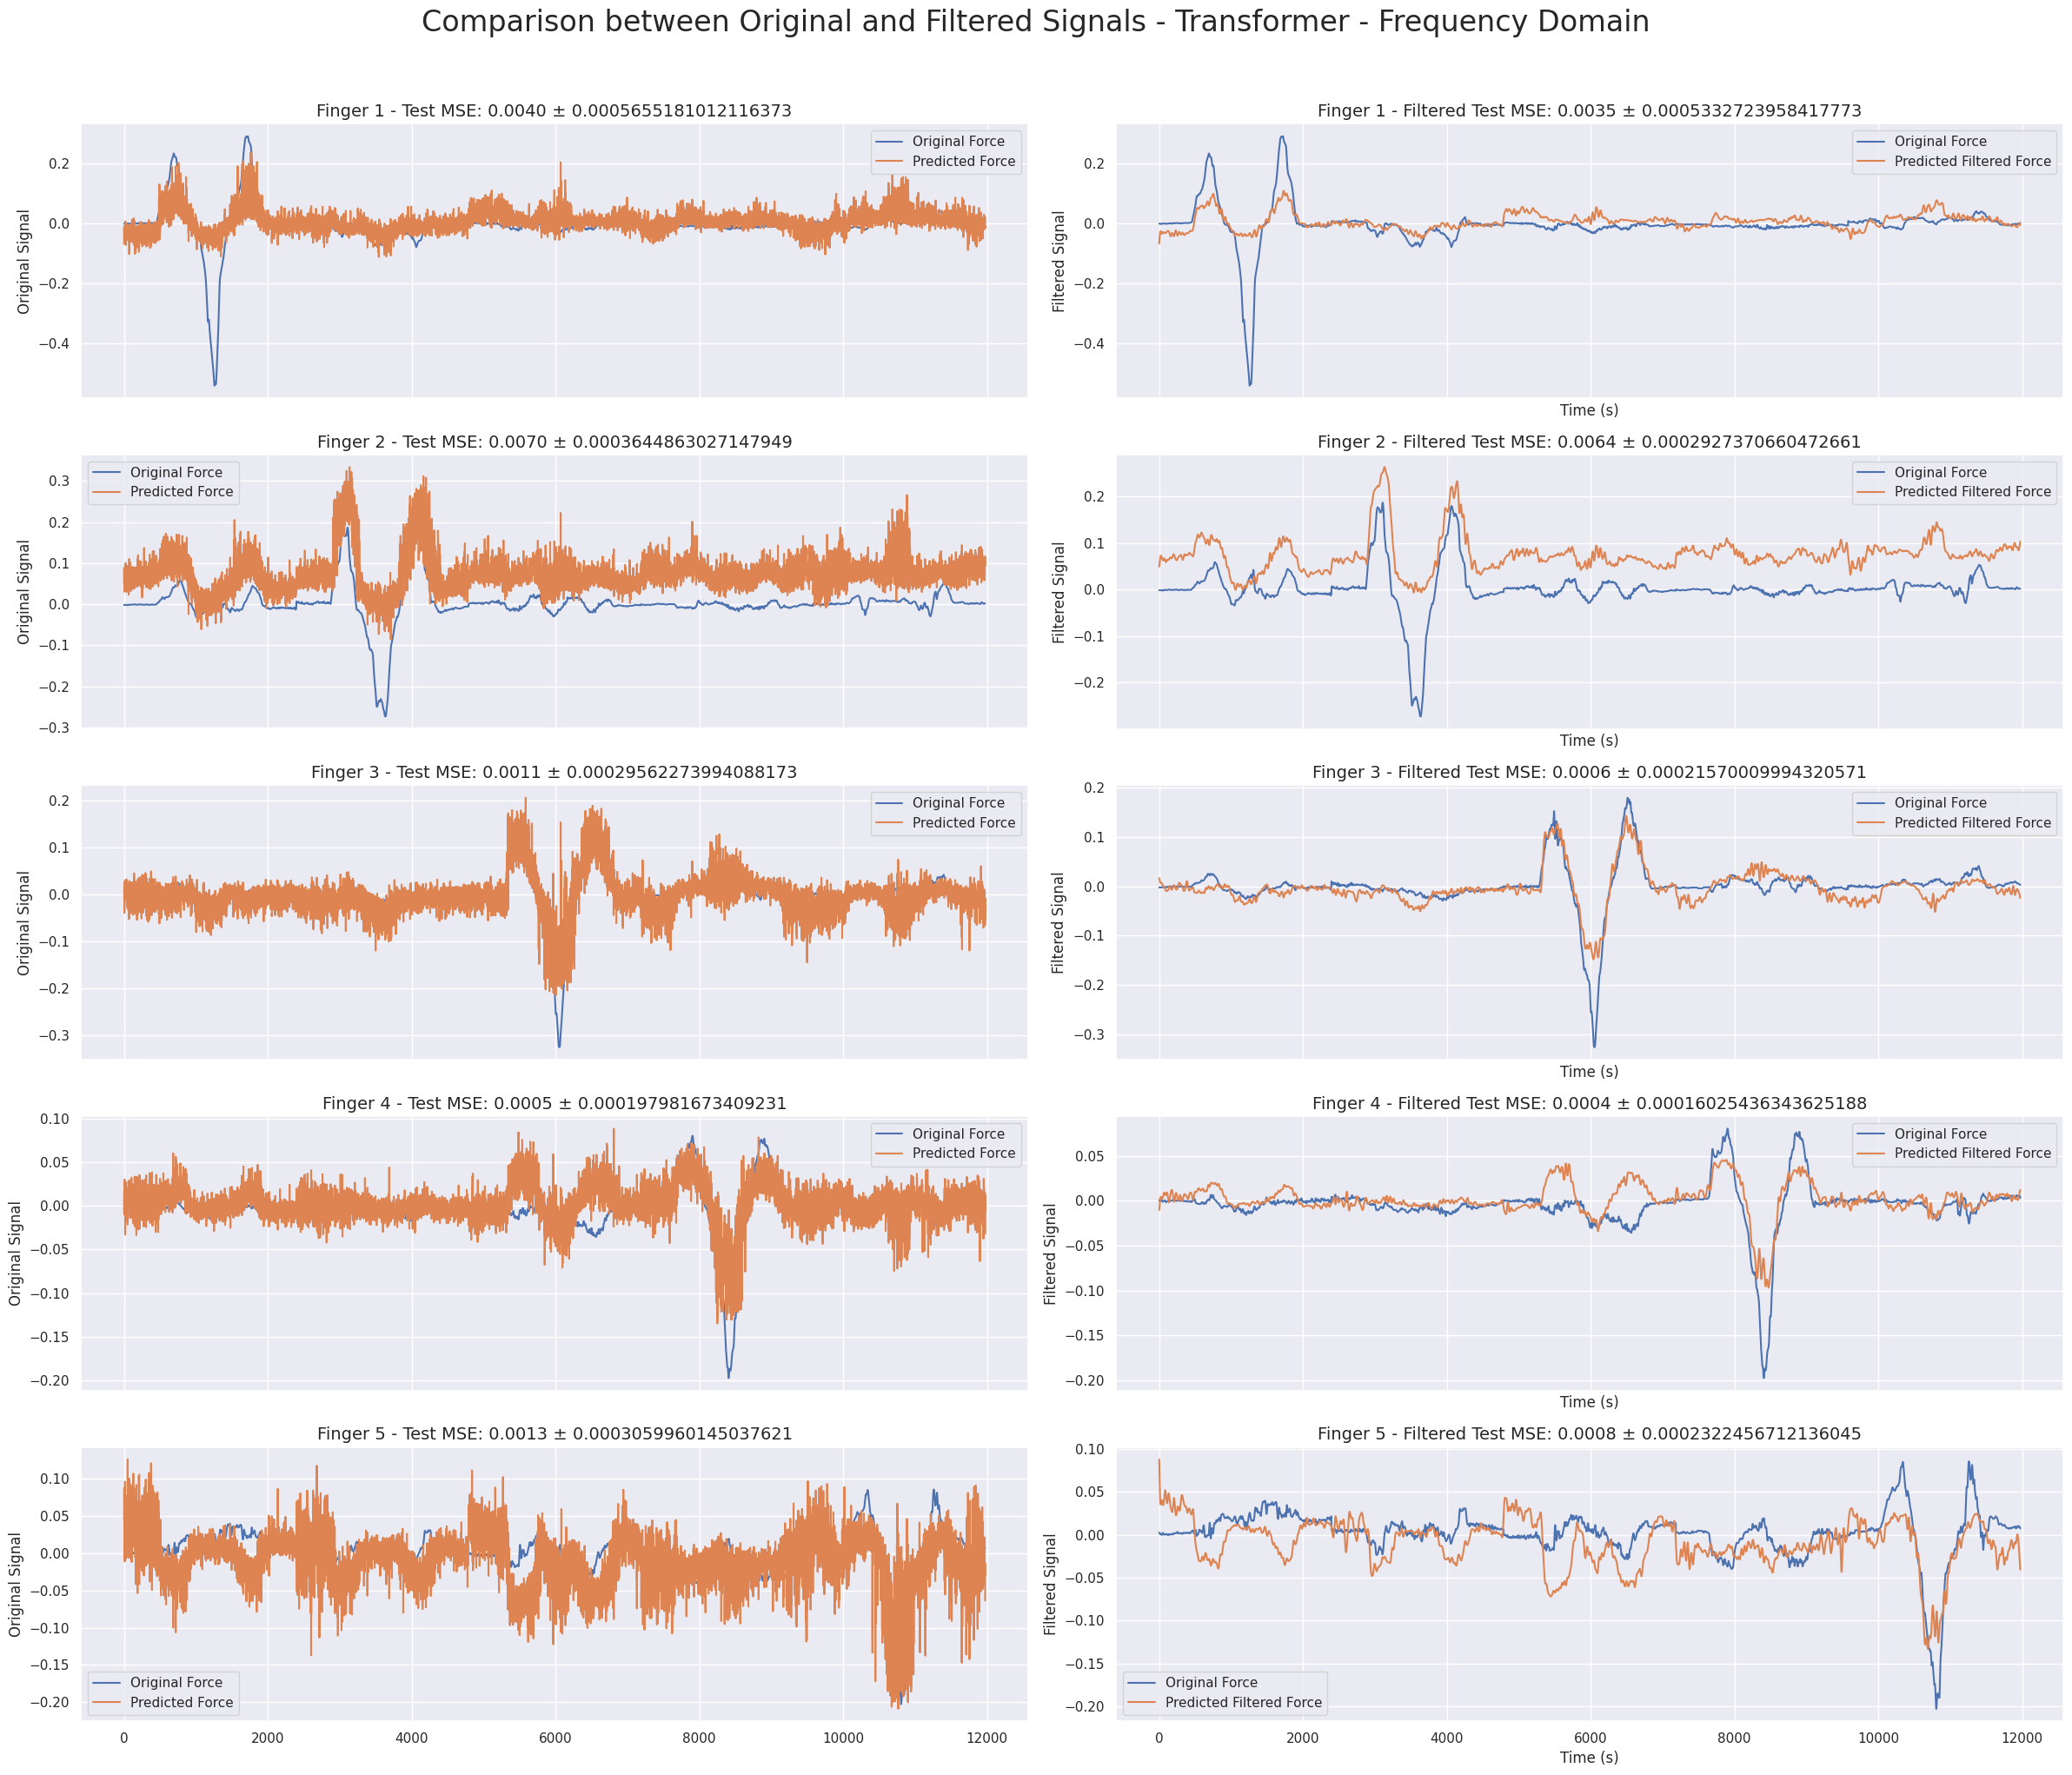

In [54]:
from scipy.signal import butter, filtfilt, iirnotch

plus_minus = "\u00B1"

def butter_lowpass(cutoff, fs, order=4):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return b, a

def butter_lowpass_filter(data, cutoff, fs, order=4):
    b, a = butter_lowpass(cutoff, fs, order=order)
    y = filtfilt(b, a, data, axis=0)
    return y

# Sample rate and desired cutoff frequency (in Hz)
fs = 2048.0
cutoff = 50.0

y = butter_lowpass_filter(predicted_test, cutoff, fs, order=4)

fig, ax = plt.subplots(5, 2, sharex=True, figsize=(24, 20))

for channel in range(5):
    # Calculate MSE for the original and filtered signals of the current channel
    mse_original = calc_mse(predicted_test[:, channel], outputs[:, channel])
    mse_filtered = calc_mse(y[:, channel], outputs[:, channel])
    std_derror_original = standard_error(predicted_test[:, channel], outputs[:, channel])
    std_derror_filtered = standard_error(y[:, channel], outputs[:, channel])

    # Plot the original signal and its prediction
    ax[channel, 0].set_title(f"Finger {channel + 1} - Test MSE: {mse_original:.4f} {plus_minus} {std_derror_original}", fontsize=14)
    ax[channel, 0].plot(outputs[:, channel], label='Original Force')
    ax[channel, 0].plot(predicted_test[:, channel], label='Predicted Force')
    ax[channel, 0].set_ylabel('Original Signal')
    ax[channel, 0].legend()

    # Plot the filtered signal and its prediction
    ax[channel, 1].set_title(f"Finger {channel + 1} - Filtered Test MSE: {mse_filtered:.4f} {plus_minus} {std_derror_filtered}", fontsize=14)
    ax[channel, 1].plot(outputs[:, channel], label='Original Force')
    ax[channel, 1].plot(y[:, channel], label='Predicted Filtered Force')
    ax[channel, 1].set_ylabel('Filtered Signal')
    ax[channel, 1].set_xlabel('Time (s)')
    ax[channel, 1].legend()

fig.suptitle("Comparison between Original and Filtered Signals - Transformer - Frequency Domain", fontsize=24, y=1.02)
plt.tight_layout()
plt.show()

# Training Wavenet

In [62]:
import tensorflow as tf
import einops
import keras
from keras import layers

class ResidualMain(keras.layers.Layer):
  """
    Residual block of the model with convolution, layer normalization, and
    the activation function, ReLU.
  """
  def __init__(self, filters, kernel_size):
    super().__init__()
    self.seq = keras.Sequential([
        Conv2Plus1D(filters=filters,
                    kernel_size=kernel_size,
                    padding='same'),
        layers.LayerNormalization(),
        layers.ReLU(),
        Conv2Plus1D(filters=filters,
                    kernel_size=kernel_size,
                    padding='same'),
        layers.LayerNormalization()
    ])

  def call(self, x):
    # x = tf.expand_dims(x, -2)  # Add a new channel axis
    return self.seq(x)


class Project(keras.layers.Layer):
  """
    Project certain dimensions of the tensor as the data is passed through
    different sized filters and downsampled.
  """
  def __init__(self, units):
    super().__init__()
    self.seq = keras.Sequential([
        layers.Dense(units),
        layers.LayerNormalization()
    ])

  def call(self, x):
    return self.seq(x)


def add_residual_block(input, filters, kernel_size):
  """
    Add residual blocks to the model. If the last dimensions of the input
    data and filter size does not match, project it such that last
    dimension matches.
  """
  out = ResidualMain(filters,
                     kernel_size)(input)

  res = input
  # Using the Keras functional APIs, project the last dimension of the
  # tensor to match the new filter size
  if out.shape[-1] != input.shape[-1]:
    res = Project(out.shape[-1])(res)

  return layers.add([res, out])


class ResizeSignal(keras.layers.Layer):
  def __init__(self, height, width):
    super().__init__()
    self.height = height
    self.width = width
    self.resizing_layer = layers.Resizing(self.height, self.width)

  def call(self, signal):
    """
      Use the einops library to resize the tensor.

      Args:
        Signal: Tensor representation of the signal, in the form of a set
        of frames.

      Return:
        A downsampled size of the signal according to the new height and
        width it should be resized to.
    """
    # b stands for batch size, t stands for time, h stands for height,
    # w stands for width, and c stands for the number of channels.
    old_shape = einops.parse_shape(signal, 'b t h w c')
    images = einops.rearrange(signal, 'b t h w c -> (b t) h w c')
    images = self.resizing_layer(images)
    signals = einops.rearrange(
        images, '(b t) h w c -> b t h w c',
        t = old_shape['t'])
    return signals

class Conv2Plus1D(keras.layers.Layer):
    def __init__(
        self,
        filters,
        kernel_size,
        padding,
        activation='linear',
        dilation_rate=1,
        **kwargs
        ):
        """
          A sequence of convolutional layers that first apply the convolution
          operation over the spatial dimensions, and then the temporal
          dimension.
        """
        super().__init__(**kwargs)
        self.spatial_conv = layers.Conv3D(
            filters=filters,
            kernel_size=(1, kernel_size[1], kernel_size[2]),
            padding=padding,
            activation=activation,
            dilation_rate=(1, dilation_rate, dilation_rate)
            )
        self.temporal_conv = layers.Conv3D(
            filters=filters,
            kernel_size=(kernel_size[0], 1, 1),
            padding=padding,
            activation=activation,
            dilation_rate=(dilation_rate, 1, 1)
            )
        self.batch_norm = layers.BatchNormalization()

    def call(self, x):
        x = self.spatial_conv(x)
        x = self.temporal_conv(x)
        x = self.batch_norm(x)
        x = tf.keras.activations.relu(x)
        return x

class DilatedConv2Plus1D(tf.keras.layers.Layer):
    """
    The dilation rate is set as an attribute and determines the spacing
     between the kernel elements during convolution, allowing for an
     increased receptive field.
    """
    def __init__(self, dilation_rate, filters, kernel_size, **kwargs):
        super().__init__(**kwargs)
        self.conv2plus1d = Conv2Plus1D(
            filters=filters, kernel_size=kernel_size, padding="same"
            )
        self.batchnorm = tf.keras.layers.BatchNormalization()
        self.dilation_rate = dilation_rate  # save dilation_rate as an attribute

    def call(self, x):
        x = self.conv2plus1d(x)
        x = self.batchnorm(x)
        x = tf.keras.activations.relu(x)
        return x


class Estimator(tf.keras.Model):
    """
    The WaveNet class is a neural network model that uses the
    DilatedConv2Plus1D class to build WaveNet blocks with a variable number
    of layers and dilations
    """

    def __init__(self, num_blocks, num_layers, filters, kernel_size, dilations, input_shape_, **kwargs):
        super(Estimator, self).__init__(**kwargs)
        self.num_blocks = num_blocks
        self.num_layers = num_layers
        self.filters = filters
        self.kernel_size = kernel_size
        self.dilations = dilations
        self.input_shape_ = input_shape_

        # Build the model
        self.build_model()

    def build_model(self):
        # Define input layer
        inputs = tf.keras.Input(shape=self.input_shape_)

        # Build WaveNet blocks
        x = inputs
        for i in range(self.num_blocks):
            for j in range(self.num_layers):
                dilation_rate = self.dilations[j % len(self.dilations)]
                x = DilatedConv2Plus1D(dilation_rate=dilation_rate, filters=self.filters, kernel_size=self.kernel_size)(x)
        x = tf.keras.layers.ELU()(x)
        x = tf.keras.layers.GlobalAveragePooling3D()(x)
        x = tf.keras.layers.Flatten()(x)
        outputs = layers.ReLU()(x)

        # Output layer
        # outputs = tf.keras.layers.Dense(1, activation="linear")(x)

        # Create the model
        self.model = tf.keras.Model(inputs=inputs, outputs=outputs)

    def call(self, inputs):
        return self.model(inputs)

    def summary(self):
        self.model.summary()

    def plot_model(self, show_shapes=False):
        tf.keras.utils.plot_model(
            self.model,
            show_shapes=show_shapes
        )



def estimator(
    num_blocks,
    num_layers,
    filters,
    kernel_size,
    dilations,
    input_shape_,
    # num_lstm_blocks,
    ):
    """
    The WaveNet function is a neural network model that uses the
    DilatedConv2Plus1D class to build WaveNet blocks with a variable number
    of layers and dilations
    """
    # Define input layer
    input_layer = layers.Input(shape=input_shape_)

    # Build WaveNet blocks
    x = input_layer
    for i in range(num_blocks):
        for j in range(num_layers):
            dilation_rate = dilations[j % len(dilations)]
            x = DilatedConv2Plus1D(
                dilation_rate=dilation_rate,
                filters=filters,
                kernel_size=kernel_size
            )(x)
    x = layers.ELU()(x)
    # Add residual blocks
    for i in range(num_blocks):
        x = add_residual_block(x, filters*(i+1), (18, 3, 3))
        x = ResizeSignal(x.shape[2] // 2*(i+1), x.shape[3] // 2*(i+1))(x)
    x = layers.GlobalAveragePooling3D()(x)
    x = layers.Flatten()(x)
    x = layers.ReLU()(x)
    # Linear combinator layer
    # x = layers.Dense(1, activation="linear")(x)
    # Create the Keras model
    model = tf.keras.Model(inputs=input_layer, outputs=x)

    return model

In [63]:
kernel_size=(18, 3, 3)
dilations=[1, 2, 4]
input_shape = [100, 16, 16, 1]

In [64]:
wavenet = estimator(
    num_blocks=2, num_layers=2, filters=16,
    kernel_size=kernel_size, dilations=dilations,
    input_shape_=input_shape,
)

# Define o modelo completo

inputs = tf.keras.layers.Input(shape=(100, 16, 16, 1))

latent = wavenet(inputs)
latent = layers.Dense(128, activation=tf.keras.activations.swish)(latent)
latent = layers.Dense(128, activation='linear')(latent)
outputs = layers.Dense(5, activation='linear')(latent)

wavenet = tf.keras.Model(inputs,  outputs)

In [65]:
model2 = tf.keras.Sequential([
    data_augmentation,
    wavenet,
])

In [66]:
def sse(y_true, y_pred):
    return tf.reduce_sum(tf.square(y_true - y_pred))

### Callbacks

In [67]:
callback = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath="gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/wavenet/all_fingers/",
        monitor="val_loss",
        verbose=1,
        save_best_only=True,
        save_weights_only=True,
        mode="min",
        save_format="tf.saved_model"
    ),
    tf.keras.callbacks.TensorBoard(
      log_dir='gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_tensorboard/wavenet/all_fingers/',
      histogram_freq=0,
      write_graph=True,
      write_images=False,
      write_steps_per_second=False,
      update_freq='epoch',
      profile_batch=0,
      embeddings_freq=0,
      embeddings_metadata=None,
    ),
    tf.keras.callbacks.EarlyStopping(
      patience=20,
      restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.75,
        patience=5,
        min_lr=1e-8,
    ),
]

In [68]:
# Compilar o modelo
optimizer = keras.optimizers.Adam(learning_rate=1e-3)
model2.compile(optimizer=optimizer, loss='mse', metrics=['mae', sse, se])
# Fit data to model

history = model2.fit(
    train_dataset,
    epochs=200,
    validation_data=val_dataset,
    callbacks=callback,
)

Epoch 1/200
    281/Unknown - 632s 2s/step - loss: 0.0018 - mae: 0.0232 - sse: 1.1263 - se: 0.0031
Epoch 1: val_loss improved from inf to 0.00464, saving model to gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/wavenet/all_fingers/
281/281 [==============================] - 770s 3s/step - loss: 0.0018 - mae: 0.0232 - sse: 1.1263 - se: 0.0031 - val_loss: 0.0046 - val_mae: 0.0458 - val_sse: 2.9563 - val_se: 0.0052 - lr: 0.0010
Epoch 2/200
281/281 [==============================] - ETA: 0s - loss: 0.0014 - mae: 0.0196 - sse: 0.8890 - se: 0.0028
Epoch 2: val_loss improved from 0.00464 to 0.00364, saving model to gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/wavenet/all_fingers/
281/281 [==============================] - 758s 3s/step - loss: 0.0014 - mae: 0.0196 - sse: 0.8890 - se: 0.0028 - val_loss: 0.0036 - val_mae: 0.0407 - val_sse: 2.3164 - val_se: 0.0045 - lr: 0.0010
Epoch 3/200
281/281 [==============================] - ETA: 0s - loss: 0.0013 - ma

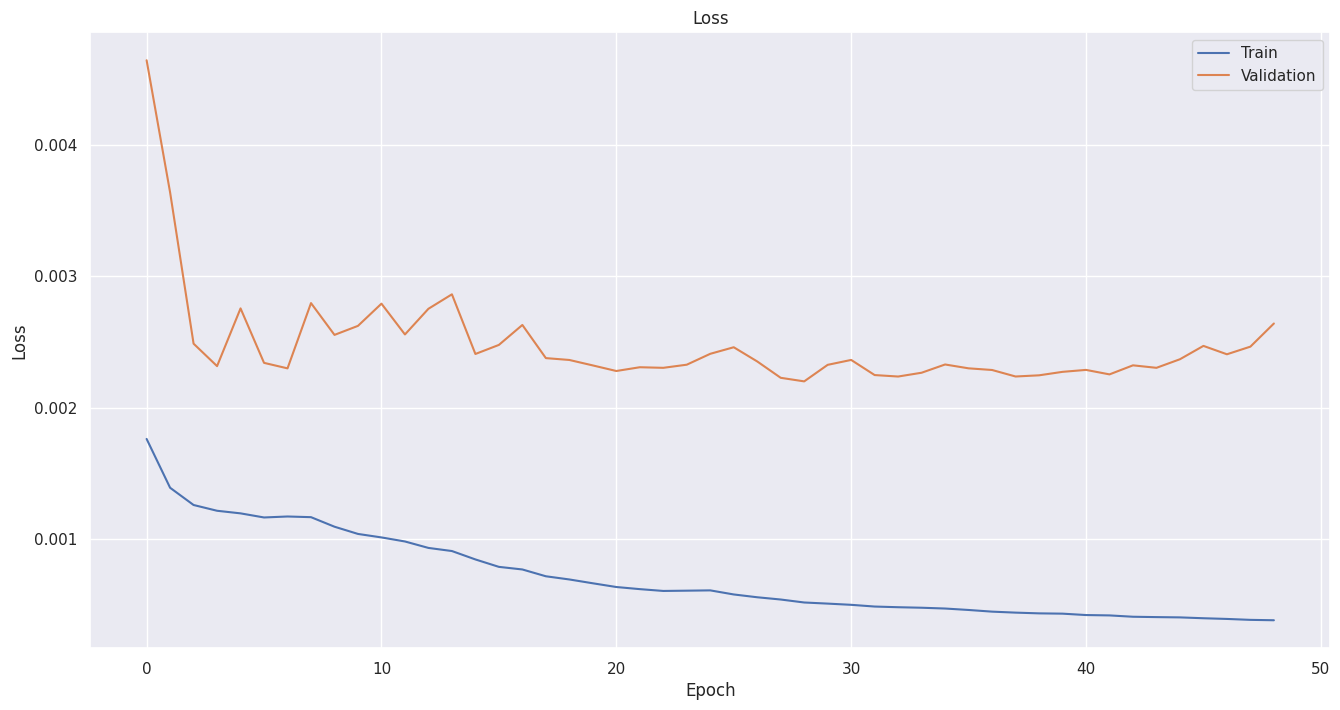

In [69]:
# Plot training & validation loss values
fig, ax = plt.subplots(figsize=(16, 8))
ax.set_title('Loss')
ax.plot(history.history['loss'], label = 'train')
ax.plot(history.history['val_loss'], label = 'test')
ax.set_ylabel('Loss')
ax.set_xlabel('Epoch')
ax.legend(['Train', 'Validation'])

## Testing

In [70]:
mse, mae, sse_, se_ = model2.evaluate(test_dataset)
print("Test MSE:", mse)
print("Test MAE:", mae)
print("Test SSE:", sse_)
print("Test SE:", se_)

94/94 [==============================] - 79s 818ms/step - loss: 0.0020 - mae: 0.0248 - sse: 1.2938 - se: 0.0029
Test MSE: 0.002031159121543169
Test MAE: 0.02480301633477211
Test SSE: 1.2937830686569214
Test SE: 0.0028662048280239105


In [ ]:
predictions, force_signal = [], []
for emg, f in test_dataset:
    prediction = model2.predict(emg)
    predictions.append(prediction)
    force_signal.append(f)

# Converter a lista de previsões em um tensor
predictions = tf.concat(predictions, axis=0)
force_signal = tf.concat(force_signal, axis=0)

In [ ]:
# predicted_test = estimator_complex.predict(emg_signal_windows_test)

In [73]:
errors = tf.keras.losses.mean_squared_error(force_signal, predictions)

print(f'mean error: {tf.reduce_mean(errors)}')
print(f'variance error: {tf.math.reduce_variance(errors)}')
print(f'r^2: {r2(force_signal, predictions)}')

mean error: 0.002031159121543169
variance error: 2.7574407795327716e-05
r^2: 0.017156177910549242


In [ ]:
predicted_test = np.array(predictions)
outputs = np.array(force_signal)

# Create subplots in a 5x1 grid
fig, axes = plt.subplots(nrows=5, ncols=1, figsize=(16, 40))

mse_ = calc_mse(predicted_test, outputs)
title = f"Wavenet test dataset: {mse_:.4f}"

for i, ax in enumerate(axes):
    mse = calc_mse(predicted_test[:, i], outputs[:, i])  # Calculate MSE for each finger separately
    ax.plot(outputs[:, i], label='Original Force')
    ax.plot(predicted_test[:, i], label='Predicted Force')
    ax.text(0, 1.15, f"Validation MSE: {mse:.4f}", transform=ax.transAxes,
            ha='center', va='center', fontsize=12)
    ax.set_title(f"Finger {i+1}")
    ax.set_xlabel("Samples")
    ax.set_ylabel("Values")

plt.suptitle(title)
plt.tight_layout()
plt.legend()
plt.show()

In [75]:
def standard_error(y_true, y_pred):
    # Calcule os resíduos (diferença entre previsões e valores reais)
    y_true = tf.cast(y_true, dtype="float32")
    y_pred = tf.cast(y_pred, dtype="float32")
    residuals = y_true - y_pred

    # Calcule o desvio padrão dos resíduos (desvio padrão da amostra)
    std_deviation = tf.math.reduce_std(residuals)

    # Tamanho da amostra (número de exemplos)
    sample_size = tf.shape(residuals)[0]

    # Calcule o erro padrão da média
    standard_error = std_deviation / tf.math.sqrt(tf.cast(sample_size, dtype=tf.float32))

    return standard_error

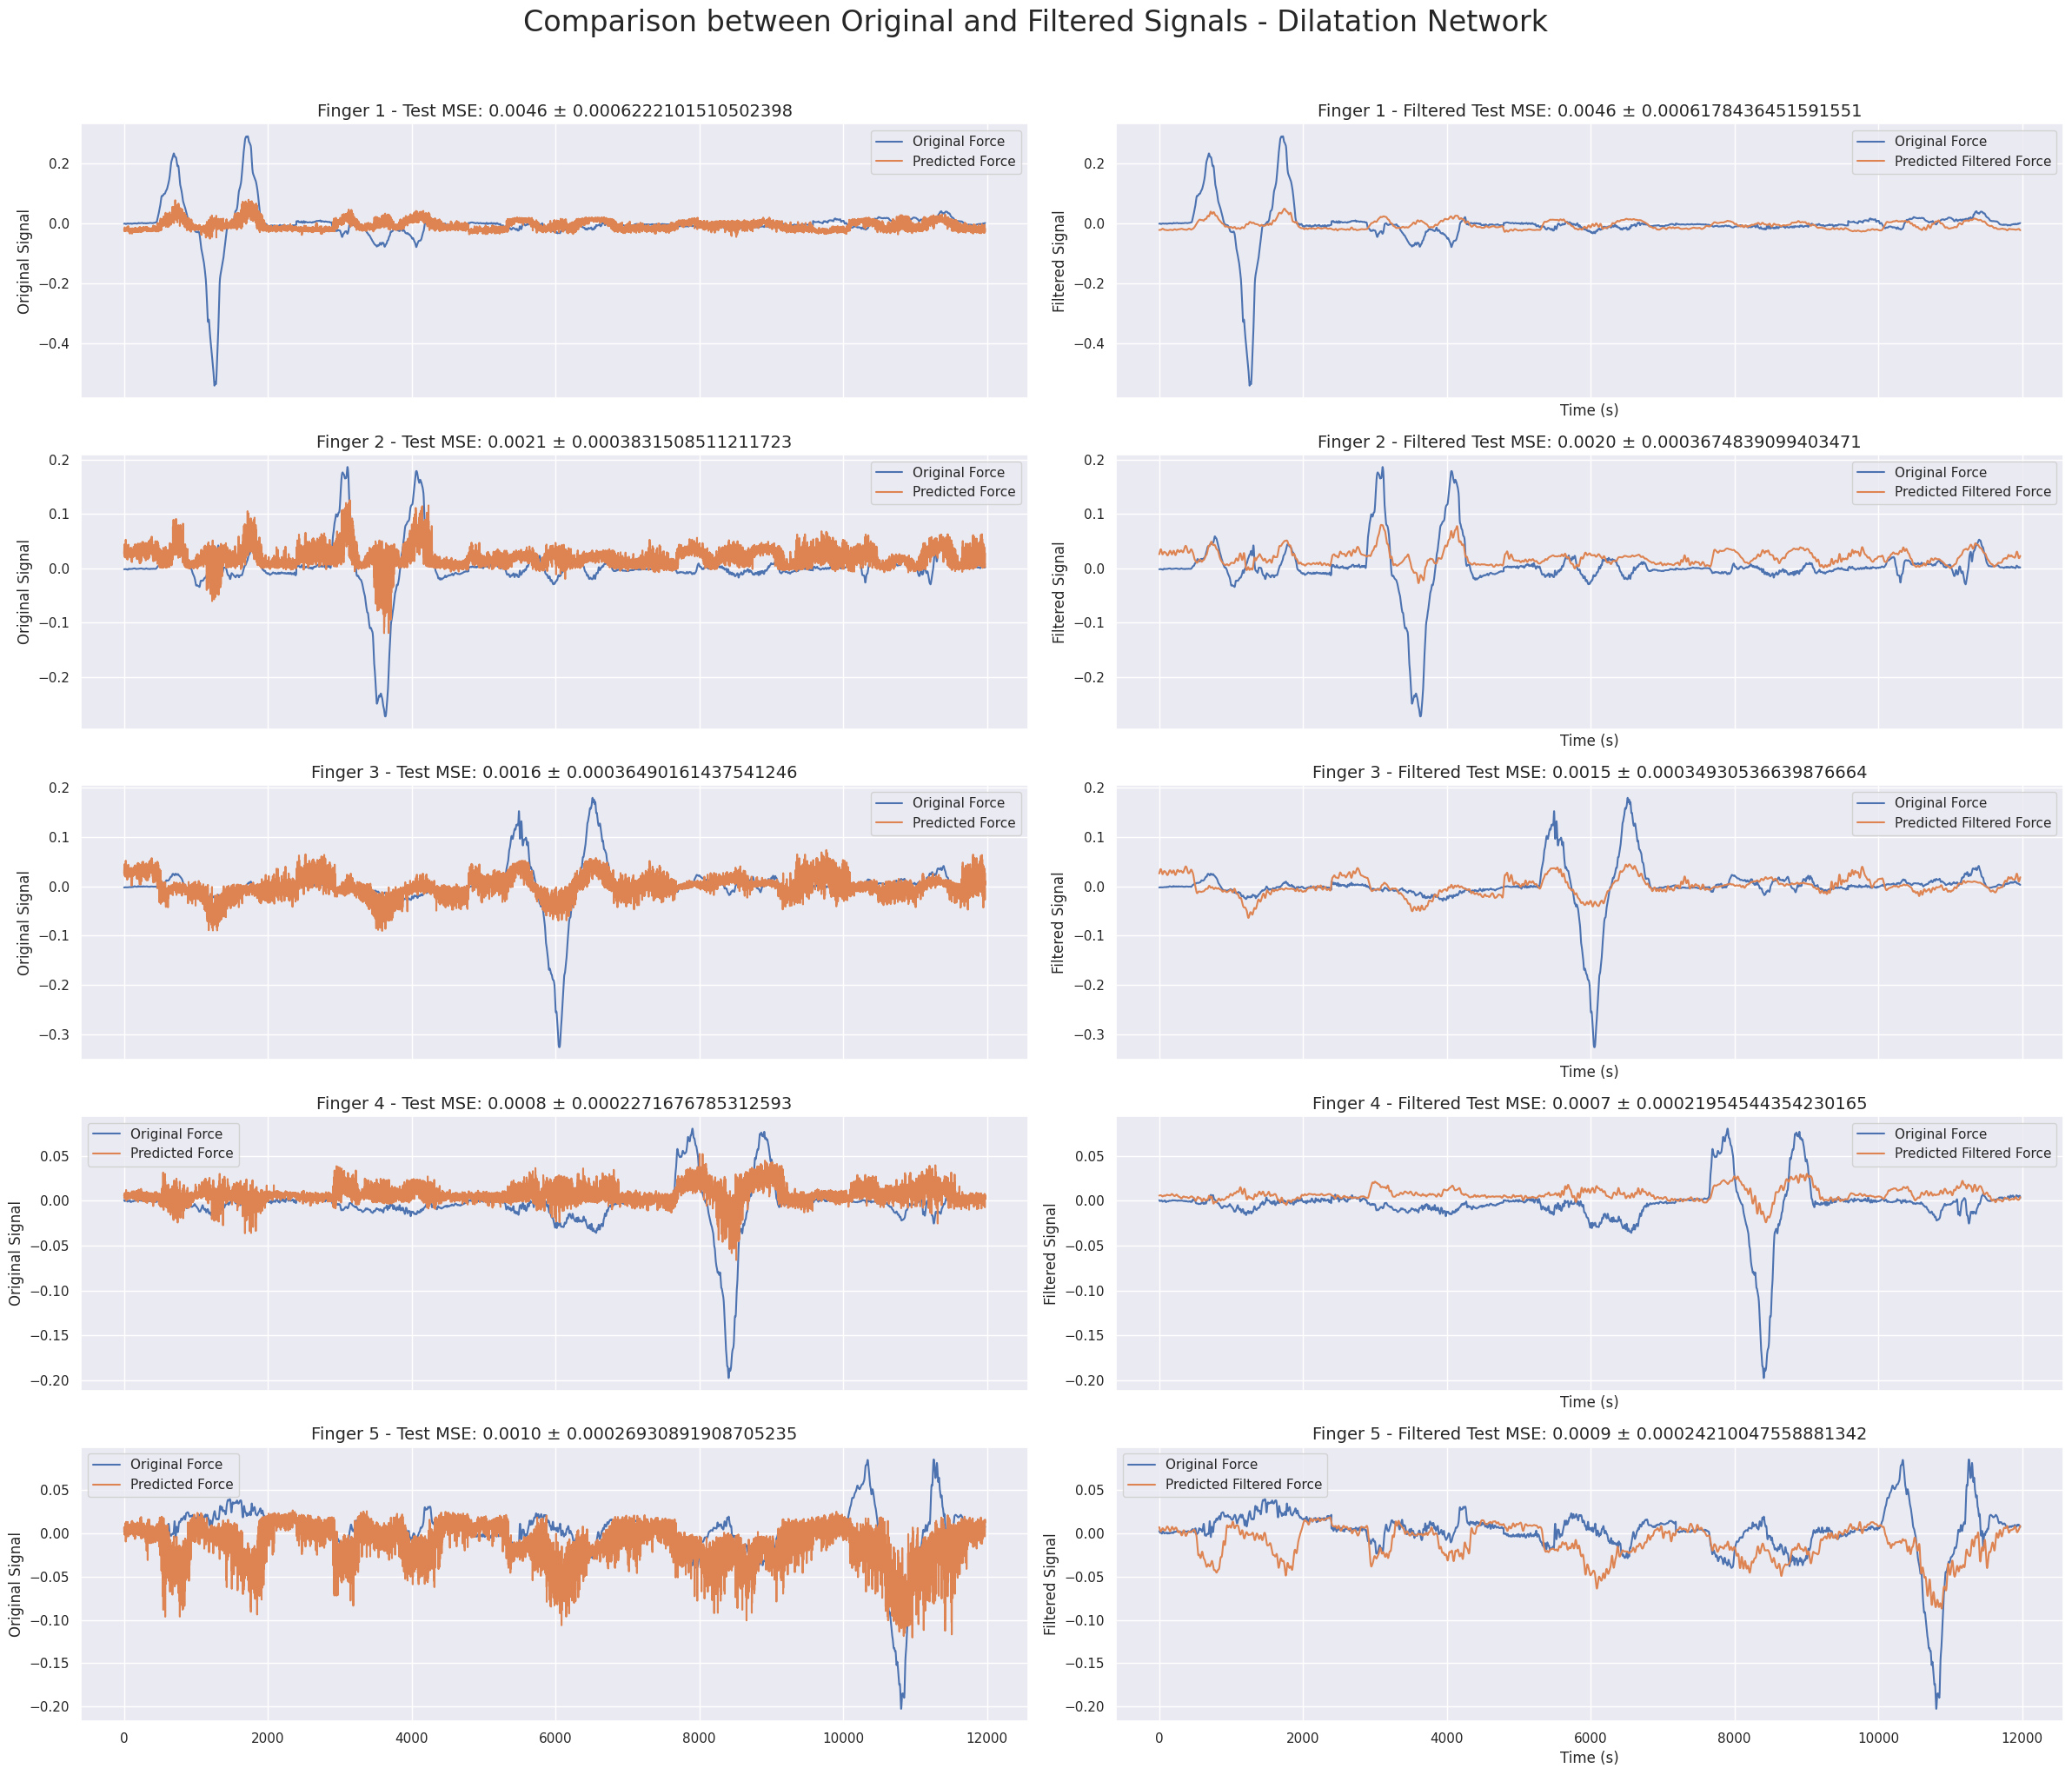

In [76]:
from scipy.signal import butter, filtfilt, iirnotch

plus_minus = "\u00B1"

def butter_lowpass(cutoff, fs, order=4):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return b, a

def butter_lowpass_filter(data, cutoff, fs, order=4):
    b, a = butter_lowpass(cutoff, fs, order=order)
    y = filtfilt(b, a, data, axis=0)
    return y

# Sample rate and desired cutoff frequency (in Hz)
fs = 2048.0
cutoff = 50.0

y = butter_lowpass_filter(predicted_test, cutoff, fs, order=4)

fig, ax = plt.subplots(5, 2, sharex=True, figsize=(24, 20))

for channel in range(5):
    # Calculate MSE for the original and filtered signals of the current channel
    mse_original = calc_mse(predicted_test[:, channel], outputs[:, channel])
    mse_filtered = calc_mse(y[:, channel], outputs[:, channel])
    std_derror_original = standard_error(predicted_test[:, channel], outputs[:, channel])
    std_derror_filtered = standard_error(y[:, channel], outputs[:, channel])

    # Plot the original signal and its prediction
    ax[channel, 0].set_title(f"Finger {channel + 1} - Test MSE: {mse_original:.4f} {plus_minus} {std_derror_original}", fontsize=14)
    ax[channel, 0].plot(outputs[:, channel], label='Original Force')
    ax[channel, 0].plot(predicted_test[:, channel], label='Predicted Force')
    ax[channel, 0].set_ylabel('Original Signal')
    ax[channel, 0].legend()

    # Plot the filtered signal and its prediction
    ax[channel, 1].set_title(f"Finger {channel + 1} - Filtered Test MSE: {mse_filtered:.4f} {plus_minus} {std_derror_filtered}", fontsize=14)
    ax[channel, 1].plot(outputs[:, channel], label='Original Force')
    ax[channel, 1].plot(y[:, channel], label='Predicted Filtered Force')
    ax[channel, 1].set_ylabel('Filtered Signal')
    ax[channel, 1].set_xlabel('Time (s)')
    ax[channel, 1].legend()

fig.suptitle("Comparison between Original and Filtered Signals - Dilatation Network", fontsize=24, y=1.02)
plt.tight_layout()
plt.show()

# Outros

In [ ]:
import tensorflow as tf
import keras
from keras import layers


from tensorflow.keras import backend as K
from tensorflow.keras import backend as K
from tensorflow.keras import activations, initializers, regularizers, constraints
from tensorflow.keras.layers import Layer, InputSpec
import numpy as np
from numpy.random import RandomState


# _compute_fans is different in keras-2 keras.initializers and tensorflow.python.ops.init_ops
# this is the implementation copied from keras-2:
def _compute_fans(shape, data_format="channels_last"):
    """Computes the number of input and output units for a weight shape.
    # Arguments

        shape: Integer shape tuple.
        data_format: Image data format to use for convolution kernels.
            Note that all kernels in Keras are standardized on the
            `channels_last` ordering (even when inputs are set
            to `channels_first`).
    # Returns
        A tuple of scalars, `(fan_in, fan_out)`.
    # Raises
        ValueError: in case of invalid `data_format` argument.
    """
    if len(shape) == 2:
        fan_in = shape[0]
        fan_out = shape[1]
    elif len(shape) in {3, 4, 5}:
        # Assuming convolution kernels (1D, 2D or 3D).
        # TH kernel shape: (depth, input_depth, ...)
        # TF kernel shape: (..., input_depth, depth)
        if data_format == "channels_first":
            receptive_field_size = np.prod(shape[2:])
            fan_in = shape[1] * receptive_field_size
            fan_out = shape[0] * receptive_field_size
        elif data_format == "channels_last":
            receptive_field_size = np.prod(shape[:2])
            fan_in = shape[-2] * receptive_field_size
            fan_out = shape[-1] * receptive_field_size
        else:
            raise ValueError("Invalid data_format: " + data_format)
    else:
        # No specific assumptions.
        fan_in = np.sqrt(np.prod(shape))
        fan_out = np.sqrt(np.prod(shape))
    return fan_in, fan_out


class ComplexDense(Layer):
    """Regular complex densely-connected NN layer.
    `Dense` implements the operation:
    `real_preact = dot(real_input, real_kernel) - dot(imag_input, imag_kernel)`
    `imag_preact = dot(real_input, imag_kernel) + dot(imag_input, real_kernel)`
    `output = activation(K.concatenate([real_preact, imag_preact]) + bias)`
    where `activation` is the element-wise activation function
    passed as the `activation` argument, `kernel` is a weights matrix
    created by the layer, and `bias` is a bias vector created by the layer
    (only applicable if `use_bias` is `True`).
    Note: if the input to the layer has a rank greater than 2, then
    AN ERROR MESSAGE IS PRINTED.
    # Arguments
        units: Positive integer, dimensionality of each of the real part
            and the imaginary part. It is actualy the number of complex units.
        activation: Activation function to use
            (see keras.activations).
            If you don't specify anything, no activation is applied
            (ie. "linear" activation: `a(x) = x`).
        use_bias: Boolean, whether the layer uses a bias vector.
        kernel_initializer: Initializer for the complex `kernel` weights matrix.
            By default it is 'complex'.
            and the usual initializers could also be used.
            (see keras.initializers and init.py).
        bias_initializer: Initializer for the bias vector
            (see keras.initializers).
        kernel_regularizer: Regularizer function applied to
            the `kernel` weights matrix
            (see keras.regularizers).
        bias_regularizer: Regularizer function applied to the bias vector
            (see keras.regularizers).
        activity_regularizer: Regularizer function applied to
            the output of the layer (its "activation").
            (see keras.regularizers).
        kernel_constraint: Constraint function applied to the kernel matrix
            (see keras.constraints).
        bias_constraint: Constraint function applied to the bias vector
            (see keras.constraints).
    # Input shape
        a 2D input with shape `(batch_size, input_dim)`.
    # Output shape
        For a 2D input with shape `(batch_size, input_dim)`,
        the output would have shape `(batch_size, units)`.
    """

    def __init__(
        self,
        units,
        activation=None,
        use_bias=True,
        init_criterion="he",
        kernel_initializer="complex",
        bias_initializer="zeros",
        kernel_regularizer=None,
        bias_regularizer=None,
        activity_regularizer=None,
        kernel_constraint=None,
        bias_constraint=None,
        seed=None,
        **kwargs
    ):
        if "input_shape" not in kwargs and "input_dim" in kwargs:
            kwargs["input_shape"] = (kwargs.pop("input_dim"),)
        super(ComplexDense, self).__init__(**kwargs)
        self.units = units
        self.activation = activations.get(activation)
        self.use_bias = use_bias
        self.init_criterion = init_criterion
        if kernel_initializer in {"complex"}:
            self.kernel_initializer = kernel_initializer
        else:
            self.kernel_initializer = initializers.get(kernel_initializer)
        self.bias_initializer = initializers.get(bias_initializer)
        self.kernel_regularizer = regularizers.get(kernel_regularizer)
        self.bias_regularizer = regularizers.get(bias_regularizer)
        self.activity_regularizer = regularizers.get(activity_regularizer)
        self.kernel_constraint = constraints.get(kernel_constraint)
        self.bias_constraint = constraints.get(bias_constraint)
        if seed is None:
            self.seed = np.random.randint(1, 10e6)
        else:
            self.seed = seed
        self.input_spec = InputSpec(ndim=2)
        self.supports_masking = True

    def build(self, input_shape):
        assert len(input_shape) == 2
        assert input_shape[-1] % 2 == 0
        input_dim = input_shape[-1] // 2
        data_format = K.image_data_format()
        kernel_shape = (input_dim, self.units)
        fan_in, fan_out = _compute_fans(kernel_shape, data_format=data_format)
        if self.init_criterion == "he":
            s = np.sqrt(1.0 / fan_in)
        elif self.init_criterion == "glorot":
            s = np.sqrt(1.0 / (fan_in + fan_out))
        rng = RandomState(seed=self.seed)

        # Equivalent initialization using amplitude phase representation:
        """modulus = rng.rayleigh(scale=s, size=kernel_shape)
        phase = rng.uniform(low=-np.pi, high=np.pi, size=kernel_shape)
        def init_w_real(shape, dtype=None):
            return modulus * K.cos(phase)
        def init_w_imag(shape, dtype=None):
            return modulus * K.sin(phase)"""

        # Initialization using euclidean representation:
        def init_w_real(shape, dtype=None):
            return rng.normal(
                size=kernel_shape,
                loc=0,
                scale=s,
            )  # .astype(dtype)

        def init_w_imag(shape, dtype=None):
            return rng.normal(size=kernel_shape, loc=0, scale=s)  # .astype(dtype)

        if self.kernel_initializer in {"complex"}:
            real_init = init_w_real
            imag_init = init_w_imag
        else:
            real_init = self.kernel_initializer
            imag_init = self.kernel_initializer

        self.real_kernel = self.add_weight(
            shape=kernel_shape,
            initializer=real_init,
            name="real_kernel",
            regularizer=self.kernel_regularizer,
            constraint=self.kernel_constraint,
        )
        self.imag_kernel = self.add_weight(
            shape=kernel_shape,
            initializer=imag_init,
            name="imag_kernel",
            regularizer=self.kernel_regularizer,
            constraint=self.kernel_constraint,
        )

        if self.use_bias:
            self.bias = self.add_weight(
                shape=(2 * self.units,),
                initializer=self.bias_initializer,
                name="bias",
                regularizer=self.bias_regularizer,
                constraint=self.bias_constraint,
            )
        else:
            self.bias = None

        self.input_spec = InputSpec(ndim=2, axes={-1: 2 * input_dim})
        self.built = True

    def call(self, inputs, **kwargs):
        input_shape = K.shape(inputs)
        input_dim = input_shape[-1] // 2
        real_input = inputs[:, :input_dim]
        imag_input = inputs[:, input_dim:]

        cat_kernels_4_real = K.concatenate([self.real_kernel, -self.imag_kernel], axis=-1)
        cat_kernels_4_imag = K.concatenate([self.imag_kernel, self.real_kernel], axis=-1)
        cat_kernels_4_complex = K.concatenate([cat_kernels_4_real, cat_kernels_4_imag], axis=0)

        output = K.dot(inputs, cat_kernels_4_complex)

        if self.use_bias:
            output = K.bias_add(output, self.bias)
        if self.activation is not None:
            output = self.activation(output)

        return output

    def compute_output_shape(self, input_shape):
        assert input_shape and len(input_shape) == 2
        assert input_shape[-1]
        output_shape = list(input_shape)
        output_shape[-1] = 2 * self.units
        return tuple(output_shape)

    def get_config(self):
        if self.kernel_initializer in {"complex"}:
            ki = self.kernel_initializer
        else:
            ki = initializers.serialize(self.kernel_initializer)
        config = {
            "units": self.units,
            "activation": activations.serialize(self.activation),
            "use_bias": self.use_bias,
            "init_criterion": self.init_criterion,
            "kernel_initializer": ki,
            "bias_initializer": initializers.serialize(self.bias_initializer),
            "kernel_regularizer": regularizers.serialize(self.kernel_regularizer),
            "bias_regularizer": regularizers.serialize(self.bias_regularizer),
            "activity_regularizer": regularizers.serialize(self.activity_regularizer),
            "kernel_constraint": constraints.serialize(self.kernel_constraint),
            "bias_constraint": constraints.serialize(self.bias_constraint),
            "seed": self.seed,
        }
        base_config = super(ComplexDense, self).get_config()
        return dict(list(base_config.items()) + list(config.items()))


class PositionalEmbedding(layers.Layer):
    def __init__(self, sequence_length, output_dim, **kwargs):
        super().__init__(**kwargs)
        self.position_embeddings = layers.Embedding(
            input_dim=sequence_length, output_dim=output_dim
        )
        self.sequence_length = sequence_length
        self.output_dim = output_dim

    def call(self, inputs):
        # The inputs are of shape: `(batch_size, frames, num_features)`
        length = tf.shape(inputs)[1]
        positions = tf.range(start=0, limit=length, delta=1)
        embedded_positions = self.position_embeddings(positions)
        return inputs + embedded_positions

    def compute_mask(self, inputs, mask=None):
        mask = tf.reduce_any(tf.cast(inputs, "bool"), axis=-1)
        return mask


class aComplexDense(layers.Layer):
    def __init__(self, units, activation=None, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.activation = activation

    def build(self, input_shape):
        print(input_shape[-1])
        self.real_kernel = self.add_weight(
            "real_kernel", shape=(input_shape[-1], self.units), initializer="random_normal", trainable=True
        )
        self.imag_kernel = self.add_weight(
            "imag_kernel", shape=(input_shape[-1], self.units), initializer="random_normal", trainable=True
        )
        if self.activation is not None:
            self.activation = tf.keras.activations.get(self.activation)

    def call(self, inputs):
        real = inputs[:, :, :, 0]
        imag = inputs[:, :, :, 1]
        real_output = tf.matmul(real, self.real_kernel) - tf.matmul(imag, self.imag_kernel)
        imag_output = tf.matmul(real, self.imag_kernel) + tf.matmul(imag, self.real_kernel)

        if self.activation is not None:
            real_output = self.activation(real_output)
            imag_output = self.activation(imag_output)

        return tf.stack([real_output, imag_output], axis=-1)


class TransformerEncoder(layers.Layer):
    def __init__(self, embed_dim, dense_dim, num_heads, **kwargs):
        super().__init__(**kwargs)
        self.embed_dim = embed_dim
        self.dense_dim = dense_dim
        self.num_heads = num_heads
        self.attention = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=embed_dim, dropout=0.3
        )
        self.dense_proj = keras.Sequential(
            [ComplexDense(dense_dim, activation=tf.nn.gelu), ComplexDense(embed_dim//2),]
        )
        self.layernorm_1 = layers.LayerNormalization()
        self.layernorm_2 = layers.LayerNormalization()

    def call(self, inputs, mask=None):
        if mask is not None:
            mask = mask[:, tf.newaxis, :]

        attention_output = self.attention(inputs, inputs, attention_mask=mask)
        proj_input = self.layernorm_1(inputs + attention_output)

        # Reshape proj_input to have shape (batch_size * frames, features)
        batch_size, frames, features, channels = proj_input.shape
        reshaped_proj_input = tf.reshape(proj_input, (batch_size * frames * channels, features))
        print(reshaped_proj_input.shape)
        proj_output = self.dense_proj(reshaped_proj_input)
        # Reshape proj_output back to (batch_size, frames, features)
        reshaped_proj_output = tf.reshape(proj_output, (batch_size, frames, features, -1))
        return self.layernorm_2(proj_input + reshaped_proj_output)


class SignalAnalyser(keras.layers.Layer):
    def __init__(self, sequence_length=100, embed_dim=256, dense_dim=4, num_heads=1, **kwargs):
        super(SignalAnalyser, self).__init__(**kwargs)
        self.sequence_length = sequence_length
        self.embed_dim = embed_dim
        self.positional_embedding = PositionalEmbedding(
            sequence_length,
            embed_dim,
            name="frame_position_embedding"
        )
        self.transformer = TransformerEncoder(
            embed_dim,
            dense_dim,
            num_heads,
            name="transformer_encoder"
        )
        self.global_average_pooling = tf.keras.layers.GlobalAveragePooling1D()

    def call(self, inputs):
        real = self.positional_embedding(inputs[:, :, :, 0])
        imag = self.positional_embedding(inputs[:, :, :, 1])

        concatenated_output = tf.stack([real, imag], axis=-1)

        x = self.transformer(concatenated_output)
        x = tf.reshape(x, (inputs.shape[0], self.sequence_length, self.embed_dim * 2))
        x = self.global_average_pooling(x)
        x = layers.Dense(128, activation=tf.keras.activations.swish)(x)
        return x

input_shape = (2, 100, 256, 2)
inputs = tf.random.normal(input_shape)

# Criar uma instância do modelo
analyser = SignalAnalyser(sequence_length=100, embed_dim=256)

# Realizar a análise
output = analyser(inputs)

# Verificar a dimensão do resultado
print(output.shape)

In [ ]:
import tensorflow as tf
import keras
from keras import layers

class PositionalEmbedding(layers.Layer):
    def __init__(self, sequence_length, output_dim, **kwargs):
        super().__init__(**kwargs)
        self.position_embeddings = layers.Embedding(
            input_dim=sequence_length, output_dim=output_dim
        )
        self.sequence_length = sequence_length
        self.output_dim = output_dim

    def call(self, inputs):
        # The inputs are of shape: `(batch_size, frames, num_features)`
        length = tf.shape(inputs)[1]
        positions = tf.range(start=0, limit=length, delta=1)
        embedded_positions = self.position_embeddings(positions)
        return inputs + embedded_positions

    def compute_mask(self, inputs, mask=None):
        mask = tf.reduce_any(tf.cast(inputs, "bool"), axis=-1)
        return mask


class TransformerEncoder(layers.Layer):
    def __init__(self, embed_dim, dense_dim, num_heads, **kwargs):
        super().__init__(**kwargs)
        self.embed_dim = embed_dim
        self.dense_dim = dense_dim
        self.num_heads = num_heads
        self.attention = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=embed_dim, dropout=0.3
        )
        self.dense_proj = keras.Sequential([
           layers.Dense(
               dense_dim, activation=tf.nn.gelu), layers.Dense(embed_dim),
        ])
        self.layernorm_1 = layers.LayerNormalization()
        self.layernorm_2 = layers.LayerNormalization()

    def call(self, inputs, mask=None):
        if mask is not None:
            mask = mask[:, tf.newaxis, :]

        attention_output = self.attention(
            inputs, inputs, attention_mask=mask
        )
        proj_input = self.layernorm_1(inputs + attention_output)
        proj_output = self.dense_proj(proj_input)
        return self.layernorm_2(proj_input + proj_output)


class SignalAnalyser(tf.keras.layers.Layer):
    def __init__(
        self,
        sequence_length=100, embed_dim=256, num_channels=1,
        dense_dim=4, num_heads=1, **kwargs
        ):
        super(SignalAnalyser, self).__init__(**kwargs)
        self.sequence_length = sequence_length
        self.embed_dim = embed_dim
        self.num_channels = num_channels
        self.positional_embedding = PositionalEmbedding(
            sequence_length,
            embed_dim * num_channels,
            name="frame_position_embedding"
        )
        self.transformer = TransformerEncoder(
            embed_dim * num_channels,
            dense_dim,
            num_heads,
            name="transformer_encoder"
        )
        self.global_average_pooling = tf.keras.layers.GlobalAveragePooling1D()
        self.reshape = tf.keras.layers.Reshape((16, 16, num_channels))
    def call(self, inputs):
        x = layers.Reshape(
            (self.sequence_length, self.embed_dim * self.num_channels)
        )(inputs)
        x = self.positional_embedding(x)
        x = self.transformer(x)
        x = self.global_average_pooling(x)
        x = self.reshape(x)
        return x

class TransformerDecoder(tf.keras.layers.Layer):
    def __init__(self, sequence_length=100, embed_dim=256, num_channels=1, dense_dim=4, num_heads=1, **kwargs):
        super(TransformerDecoder, self).__init__(**kwargs)
        self.embed_dim = embed_dim
        self.dense_dim = dense_dim
        self.num_heads = num_heads
        self.attention = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=embed_dim * num_channels, dropout=0.3
        )
        self.dense_proj = tf.keras.Sequential([
            layers.Dense(embed_dim * num_channels, activation=tf.nn.gelu),
            layers.Dense(sequence_length),
        ])
        self.layernorm_1 = layers.LayerNormalization()
        self.layernorm_2 = layers.LayerNormalization()
        self.reshape = tf.keras.layers.Reshape((sequence_length, 16, 16, num_channels))

    def call(self, inputs):
        attention_output = self.attention(
            inputs, inputs
        )
        proj_input = self.layernorm_1(inputs + attention_output)
        proj_output = self.dense_proj(proj_input)
        x = self.layernorm_2(proj_input + proj_output)
        x = tf.transpose(x, perm=[0, 3, 1, 2])
        x = self.reshape(x)
        return x

In [ ]:
analyser = SignalAnalyser()
decoder = TransformerDecoder()
# Cria o modelo completo
inputs = tf.keras.layers.Input(shape=(100, 16, 16, 1))

latent = analyser(inputs)

reconstructed = decoder(latent)

autoencoder = tf.keras.Model(inputs,  reconstructed)

In [ ]:
def get_input_data(input_data, output_data):
    return input_data

In [ ]:
# Compile e treine o modelo
autoencoder.compile(optimizer='adam', loss='mse')

# Treine o modelo usando seus dados
autoencoder.fit(
    train_dataset[0],train_dataset[0]
    epochs=10,
    validation_data=val_dataset,
)